# EECS 182 — inspect and reproduce the evidence

**Question:** Can a different evaluation order of the same optimizer update make training faster without changing learning behavior, and how much of a local kernel improvement survives the rest of the training system?

This notebook replays **committed experimental logs on CPU**. It does not start GPU jobs, download training data, or create new training observations. Saved outputs below come from an actual execution of these cells.

**Setup once:** from the repo root run `python -m pip install -r 182/reproduce/requirements.txt`, then open this notebook and choose **Restart Kernel and Run All Cells**. The generated HTML gallery is another readable entry point. See [README.md](README.md) for scope and limitations.

In [1]:
from pathlib import Path
import importlib.util
import sys
from IPython.display import display, Markdown, Image

start = Path.cwd().resolve()
root = next((p for p in [start, *start.parents] if (p / "182/reproduce/run.py").is_file()), None)
if root is None:
    raise RuntimeError("Open the notebook inside a complete clone of 182-project.")
spec = importlib.util.spec_from_file_location("review_runner", root / "182/reproduce/run.py")
runner = importlib.util.module_from_spec(spec)
spec.loader.exec_module(runner)
output = runner.rebuild()
print("Analysis rerun only; no new training or benchmark measurements.")

Rebuilt 8 paper figures and analysis tables from 89 archived run records.
Open C:\Users\belug\Documents\ChatGPT\Productivity\182-project\182\reproduce\output\index.html
Analysis rerun only; no new training or benchmark measurements.


## Paired timing: local gains versus recoverable runtime

The original parser uses ten common same-seed, same-session comparisons (seeds 1, 2, 3, 6, 8–13). Seed 4 crosses nodes, seed 7 lacks the ablation, and seeds 5/99 are not timing comparisons. The no-matrix arm is a timing-only ablation, not a usable optimizer. A small/noisy end-to-end gain can coexist with a reliable step-loop gain.

In [2]:
mt = sys.modules["make_tables"]
rows = mt.collect_runs()
runs = mt.timing_runs(rows)
summary_rows = []
for arm in ("gram222s", "skip_matrix"):
    for scope, unit in (("all", "ms/step"), ("time", "s/run")):
        stats = mt.summary([mt.saving(runs, arm, seed, scope) for seed in mt.COMMON_SEEDS])
        summary_rows.append([arm, scope, stats["n"], f"{stats['mean']:.5f}", f"{stats['se']:.5f}", f"±{stats['ci']:.5f}", unit])
display(Markdown(mt.md_table(["arm", "scope", "pairs", "mean saving", "SE", "95% t CI half-width", "unit"], summary_rows)))
print(f"Archived run records: {len(rows)}; invalid/incomplete: {sum(not r['valid'] for r in rows)}")
print("Positive saving means faster. CI assumes independent paired differences; inspect session/run-order caveats in the report.")

| arm | scope | pairs | mean saving | SE | 95% t CI half-width | unit |
|---|---|---|---|---|---|---|
| gram222s | all | 10 | 0.05440 | 0.00632 | ±0.01430 | ms/step |
| gram222s | time | 10 | 0.04690 | 0.02062 | ±0.04664 | s/run |
| skip_matrix | all | 10 | 0.20940 | 0.00517 | ±0.01170 | ms/step |
| skip_matrix | time | 10 | 0.26520 | 0.02241 | ±0.05069 | s/run |


Archived run records: 89; invalid/incomplete: 4
Positive saving means faster. CI assumes independent paired differences; inspect session/run-order caveats in the report.


## All paper figures

Plots are regenerated from the archived logs, not copied from the checked-in images. The map plot is an algebraic illustration. Profile figures use archived category analysis; categories may overlap.

### fig_maps.png
Six scalar maps: algebraic illustration, not an experiment.

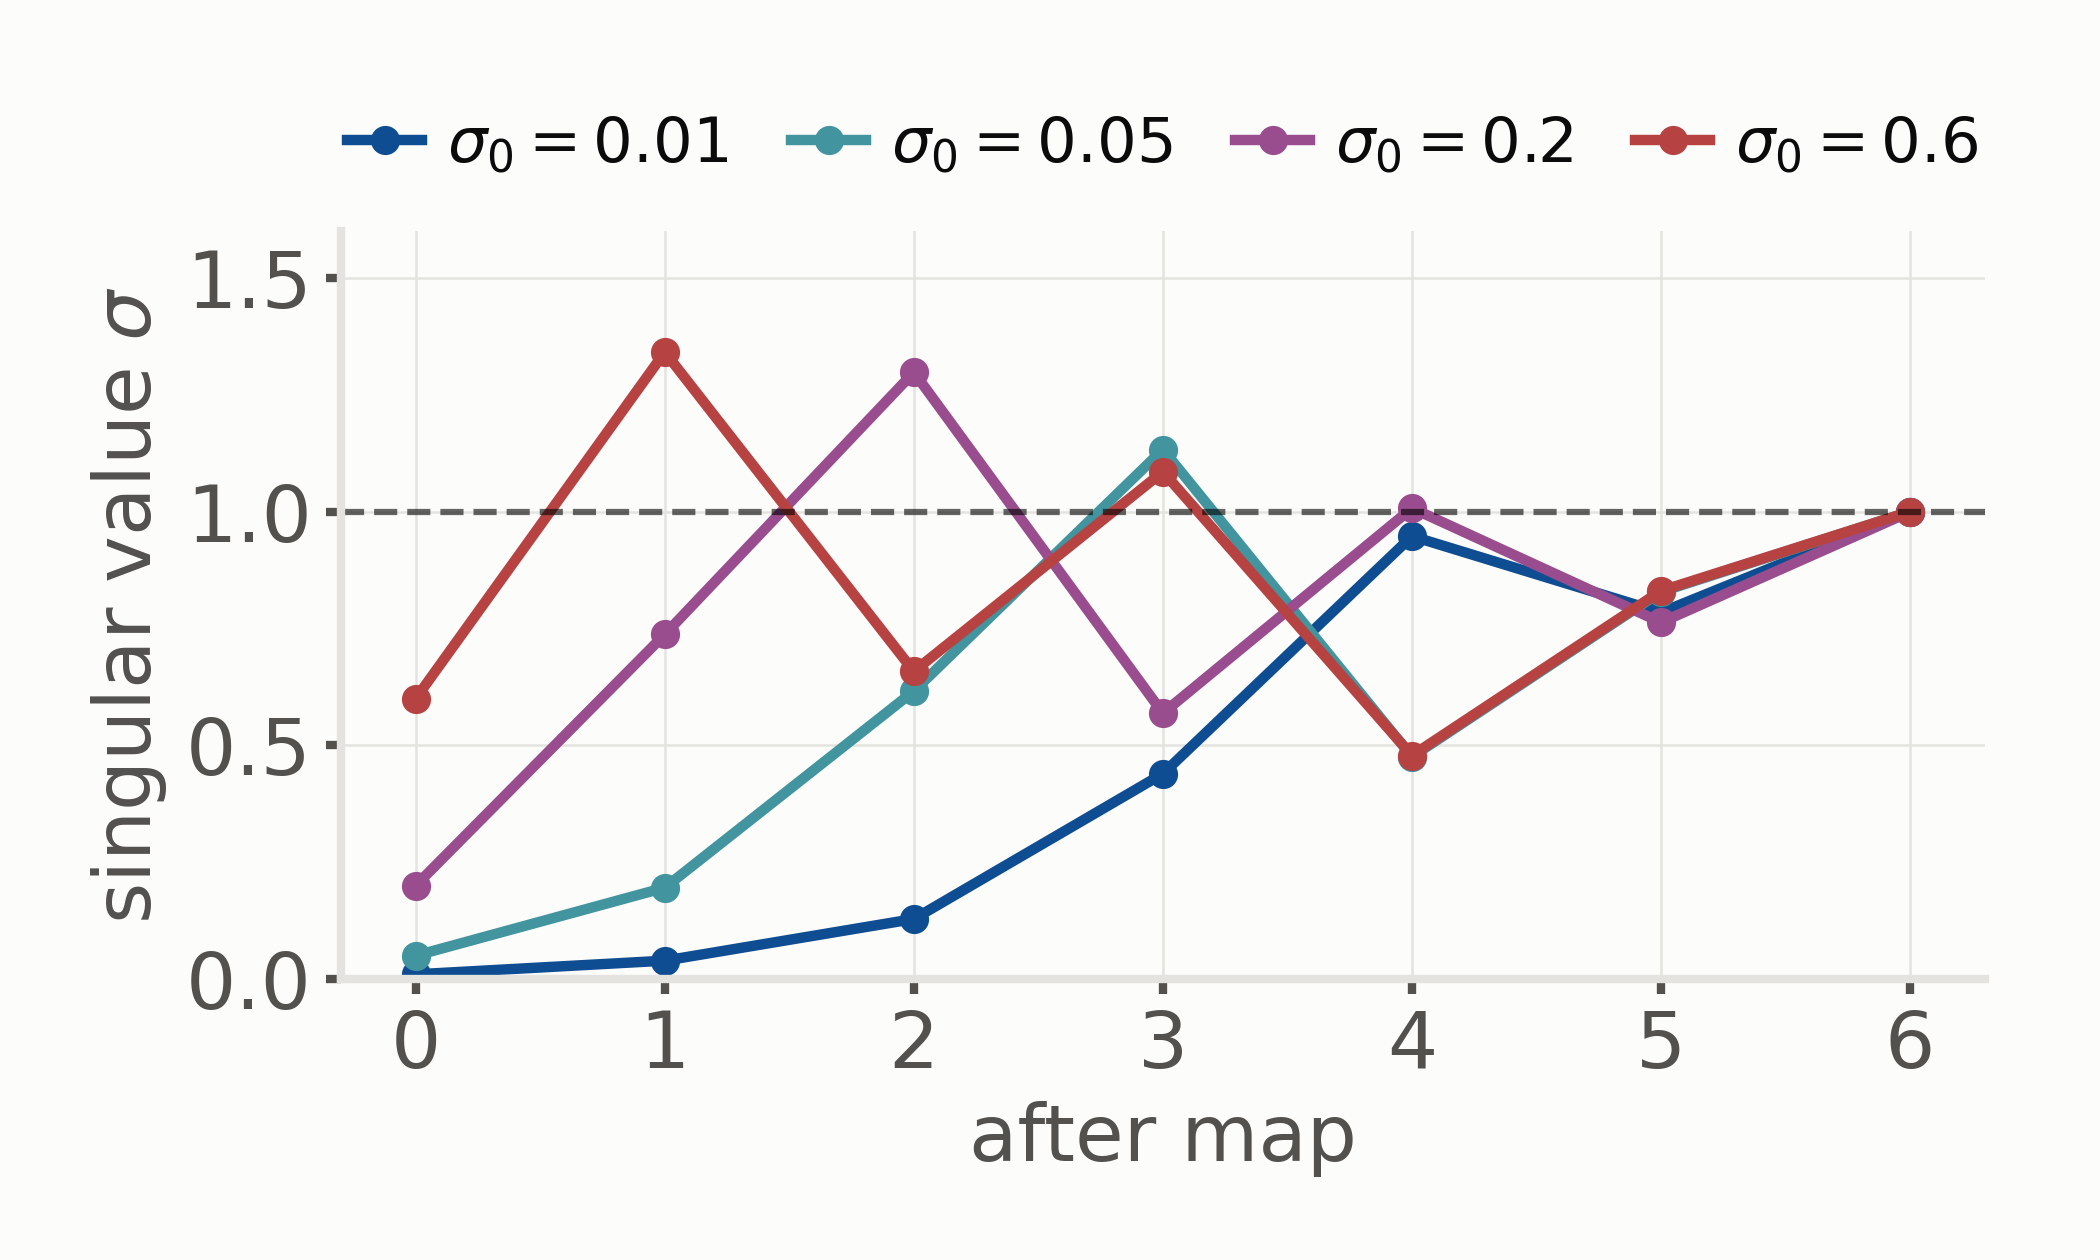

### fig_bench.png
One-H100 microbenchmark: median; whiskers are 10th–90th percentiles over 300 repetitions, not confidence intervals.

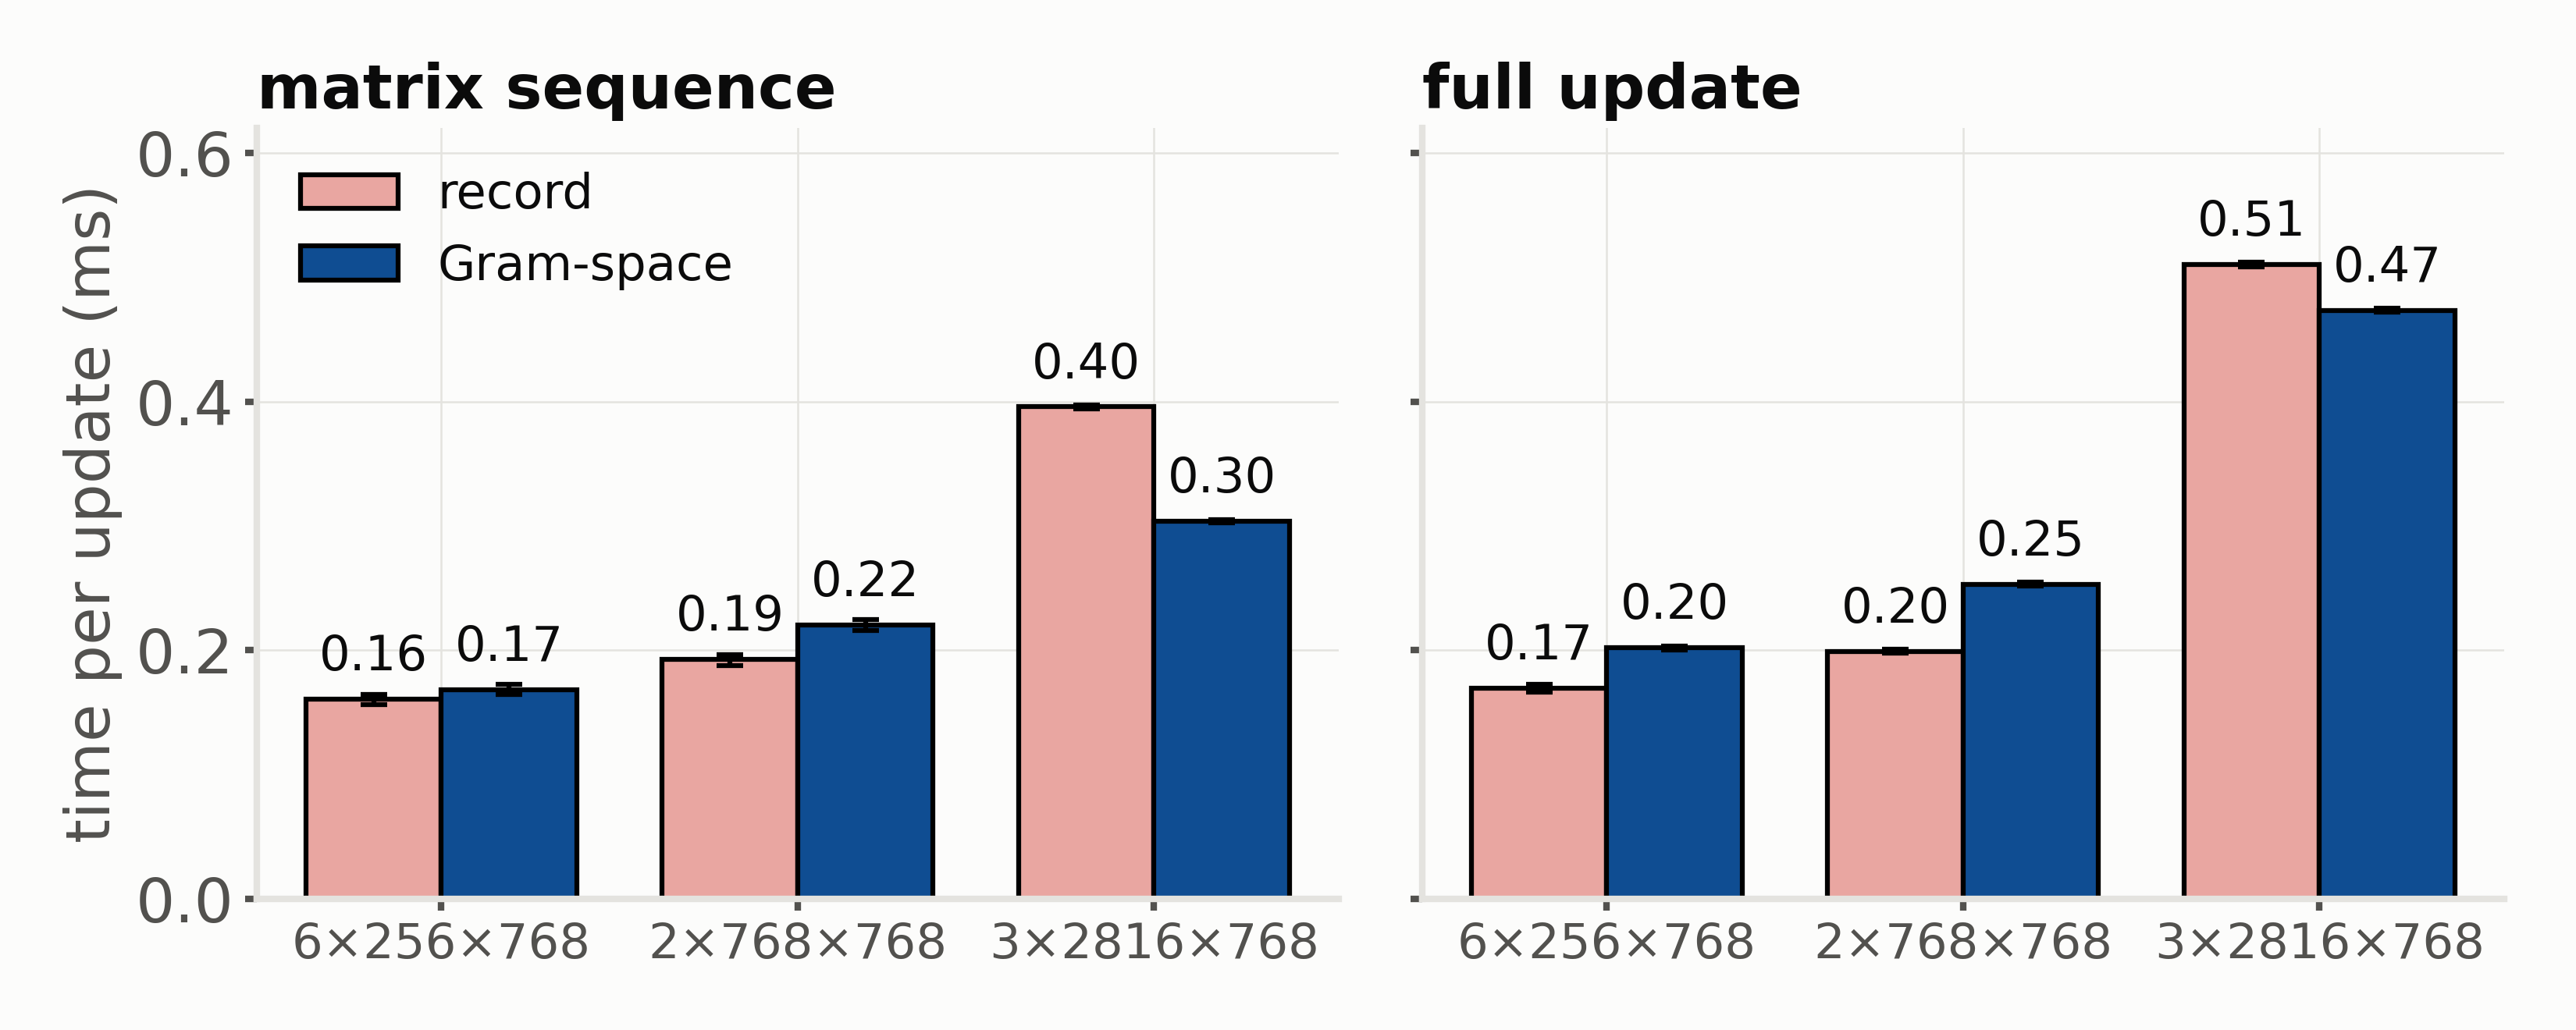

### fig_steploop.png
First-session unpaired training clock decomposition, seeds 1–3 per arm: mean ± sample SD; dots are runs. Timing excludes compilation and warm-up. Supplementary asset not included in current main.tex.

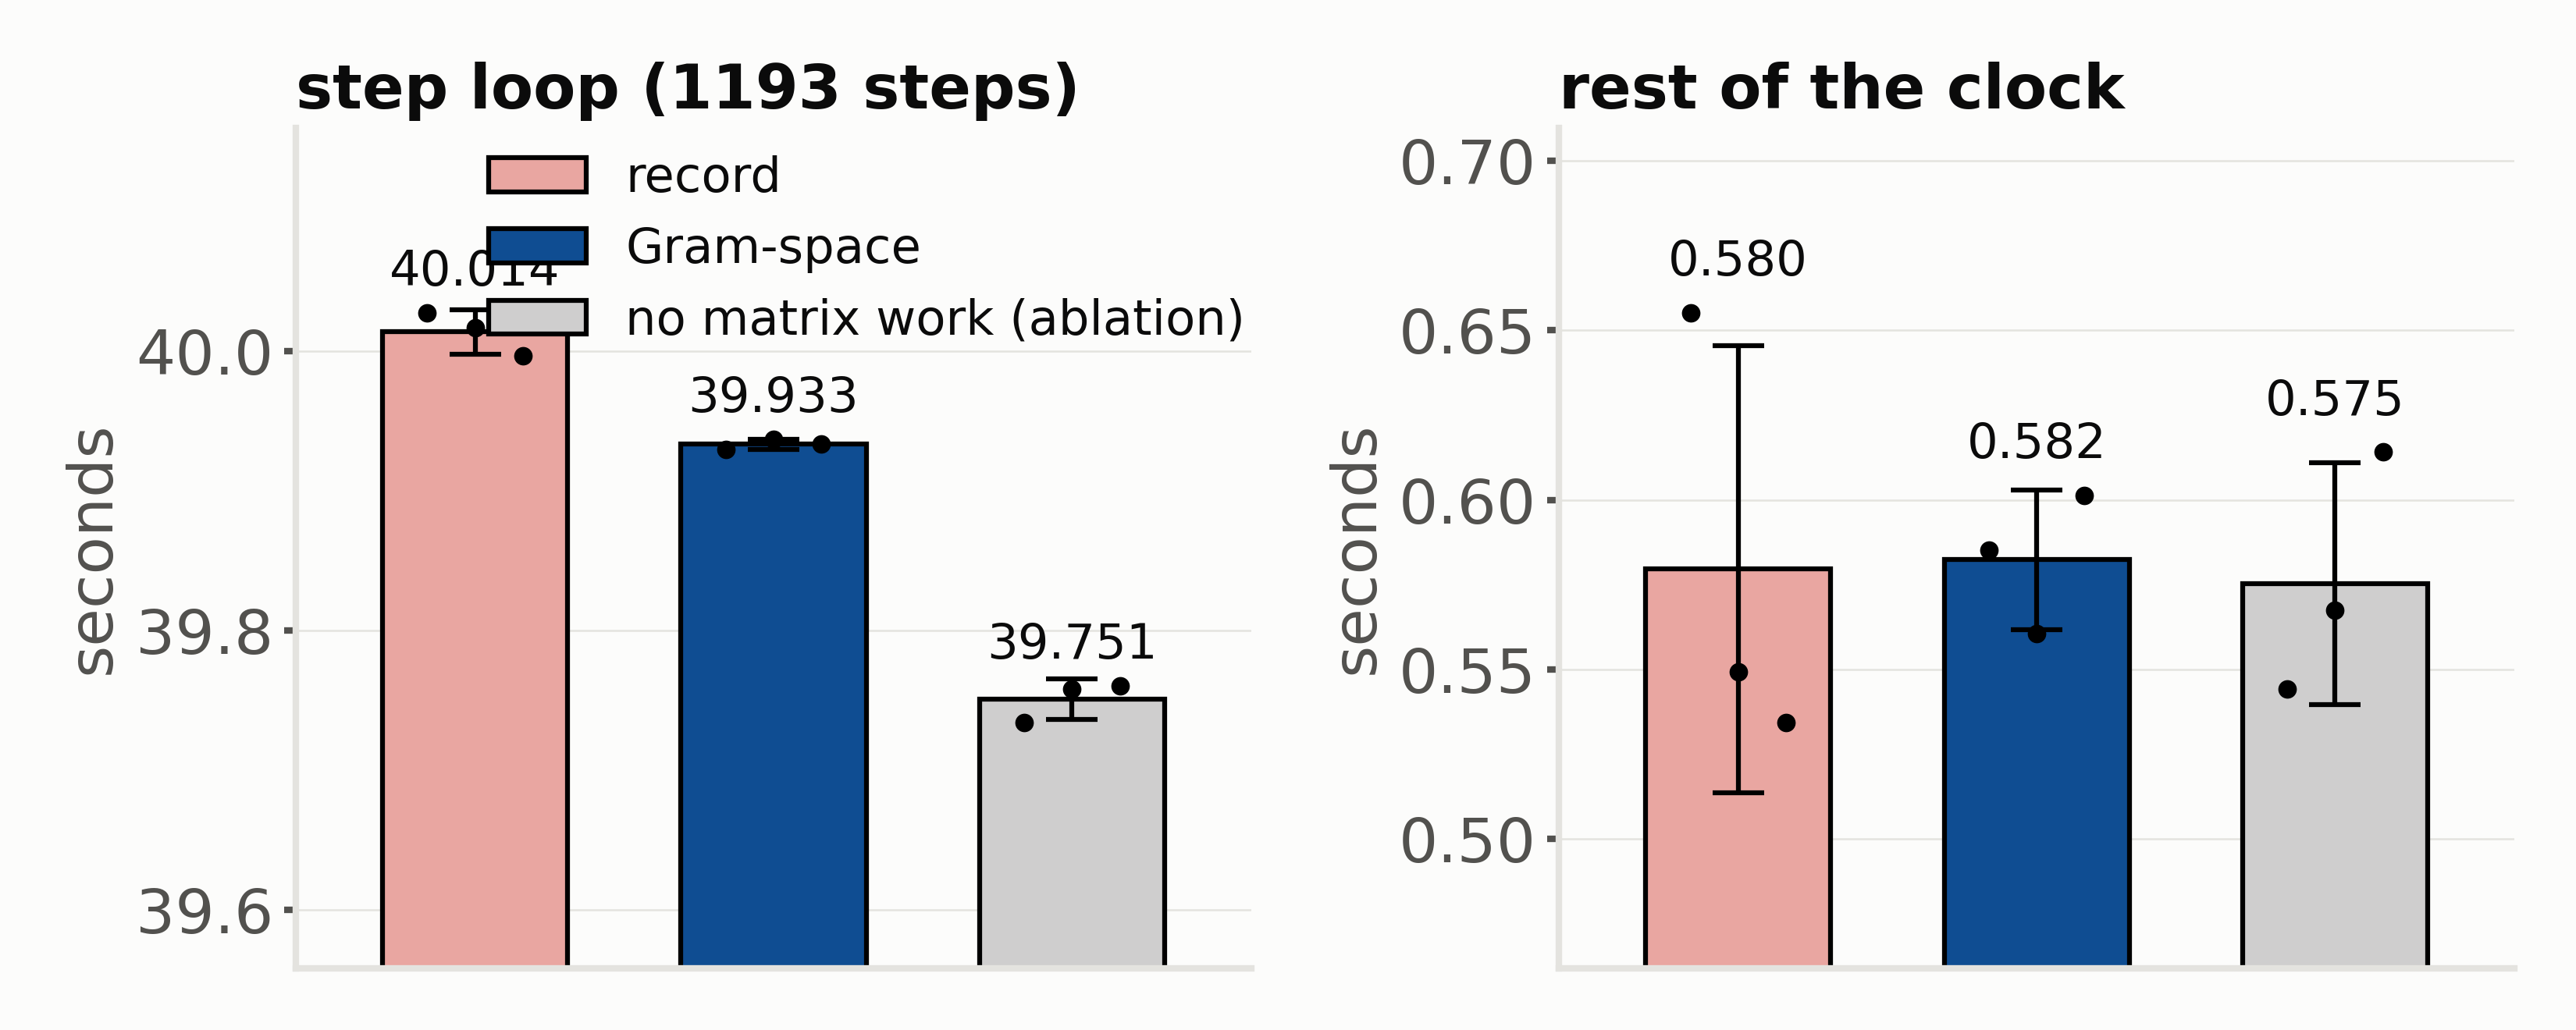

### fig_profile.png
Early rank-0 profile from archived analysis.txt; overlapping streams are not additive.

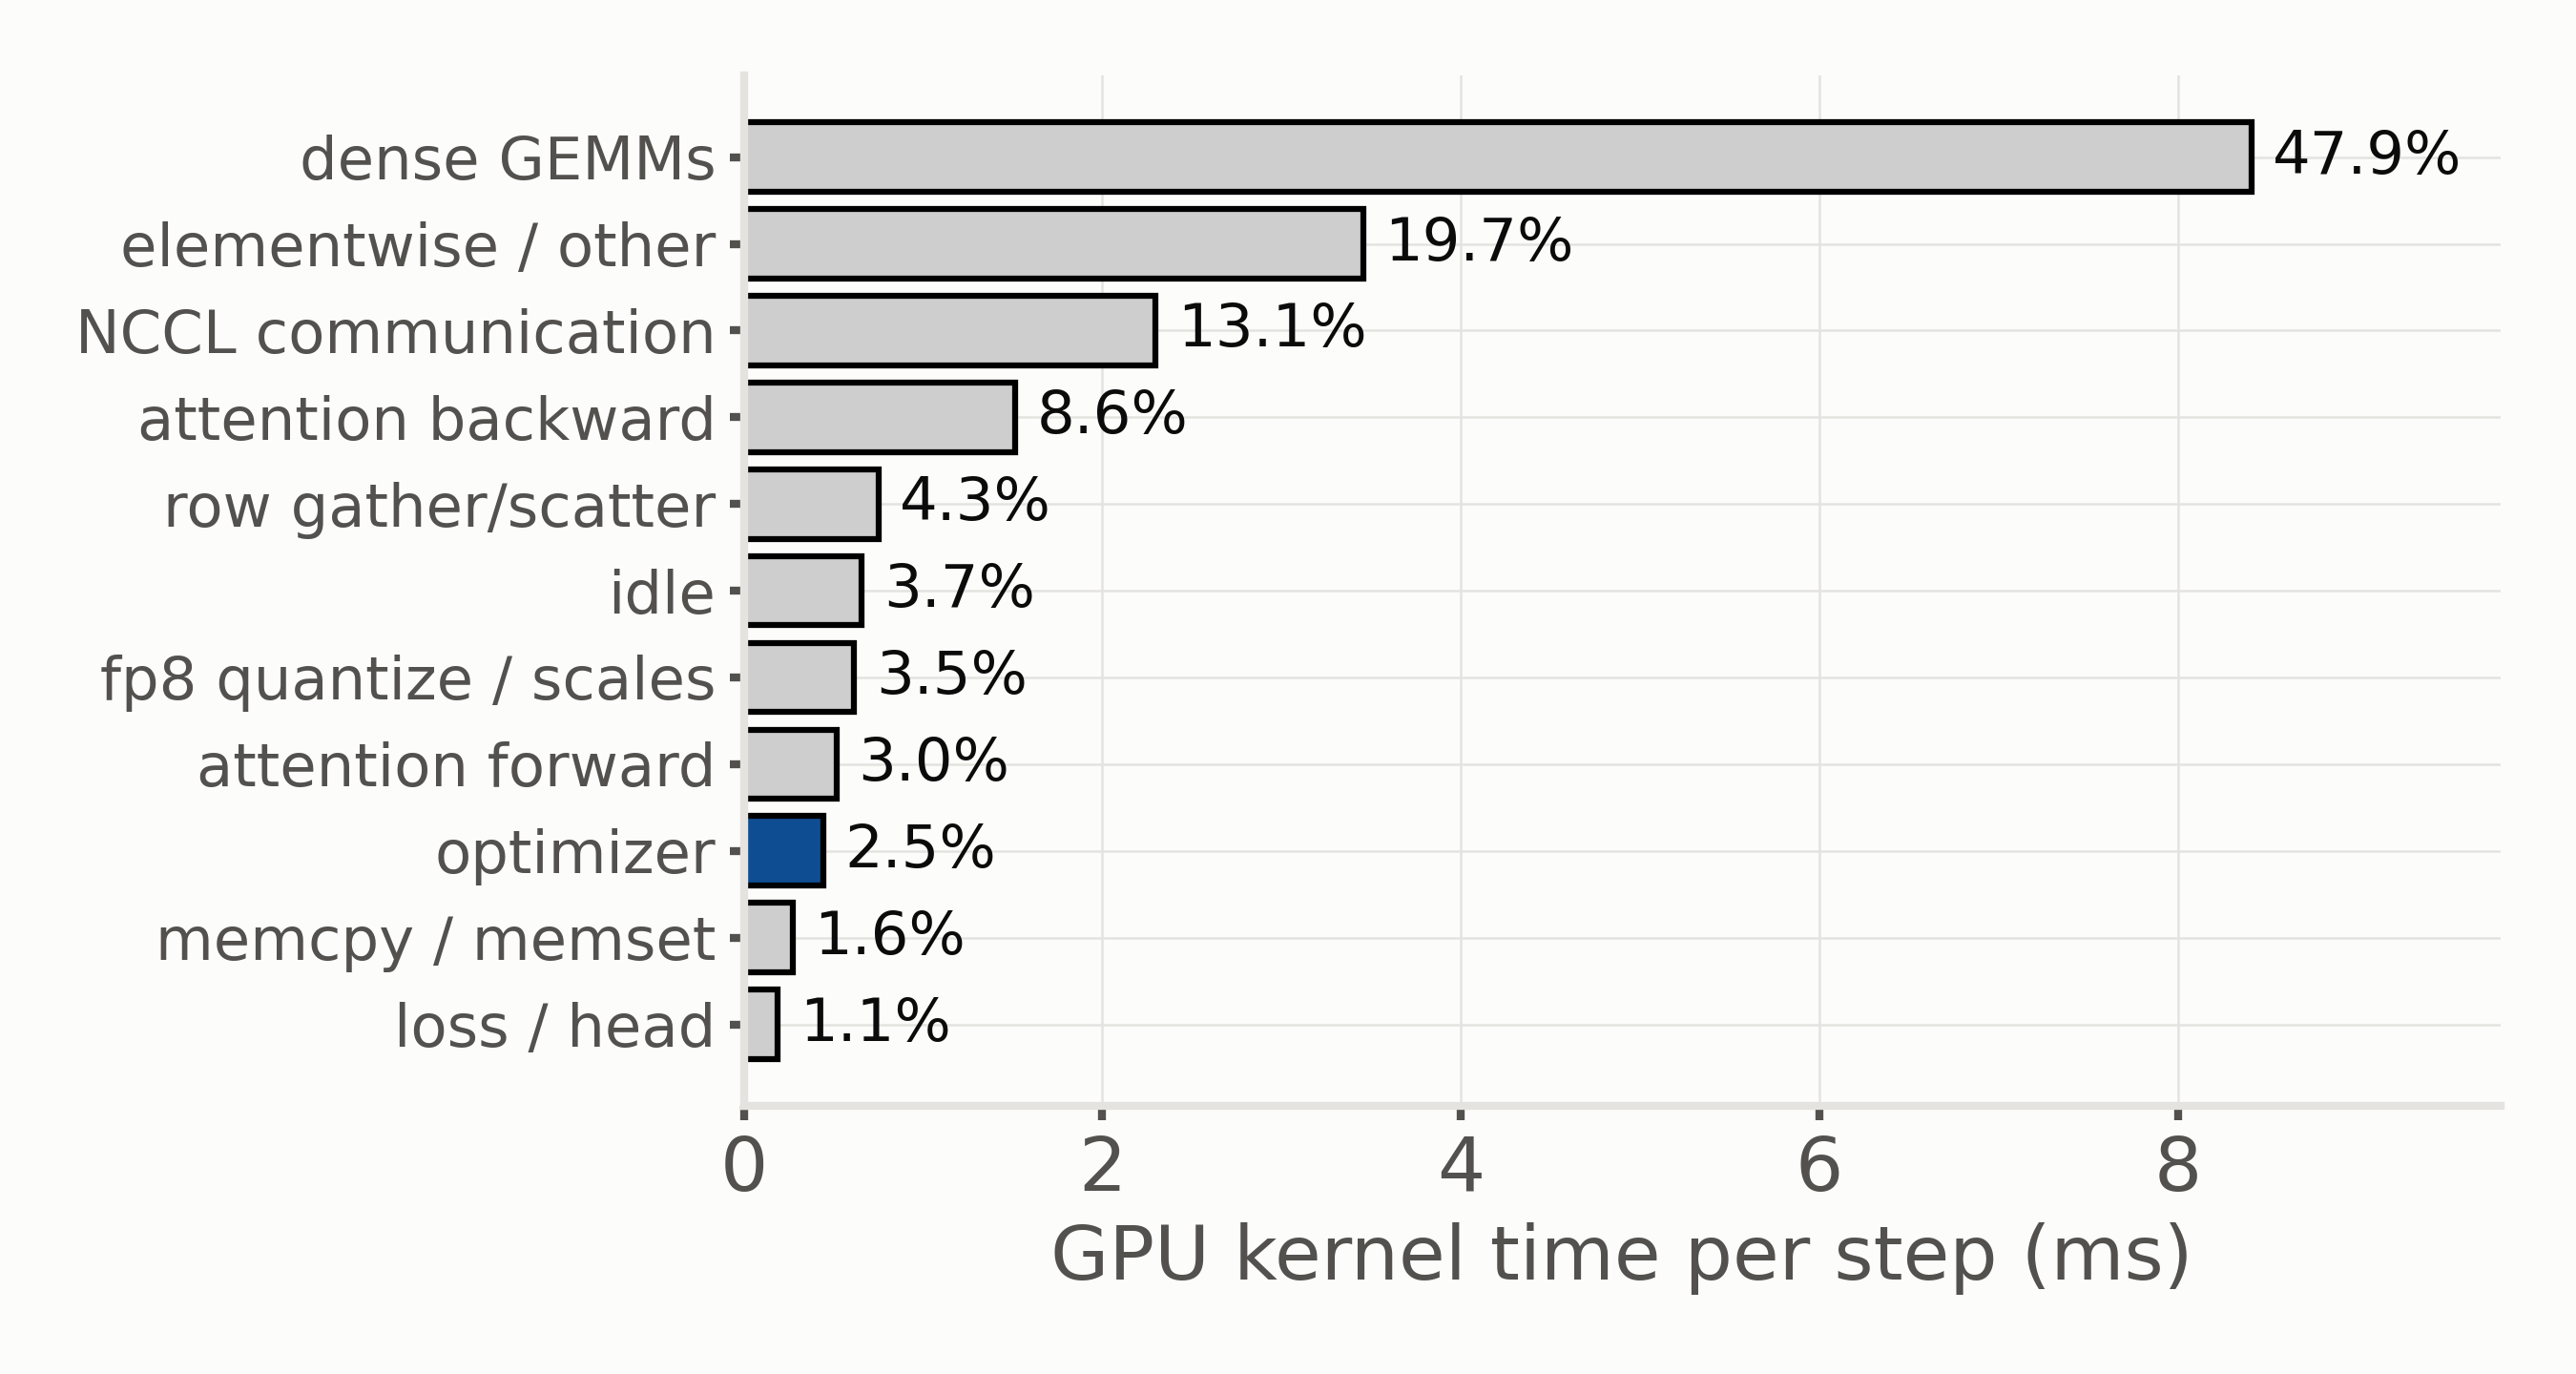

### fig_paired.png
Ten same-seed, same-session comparisons. Positive means faster. Bars show mean and sample SD, not SE or a confidence interval. Skip-matrix is a timing-only ablation, not a usable optimizer.

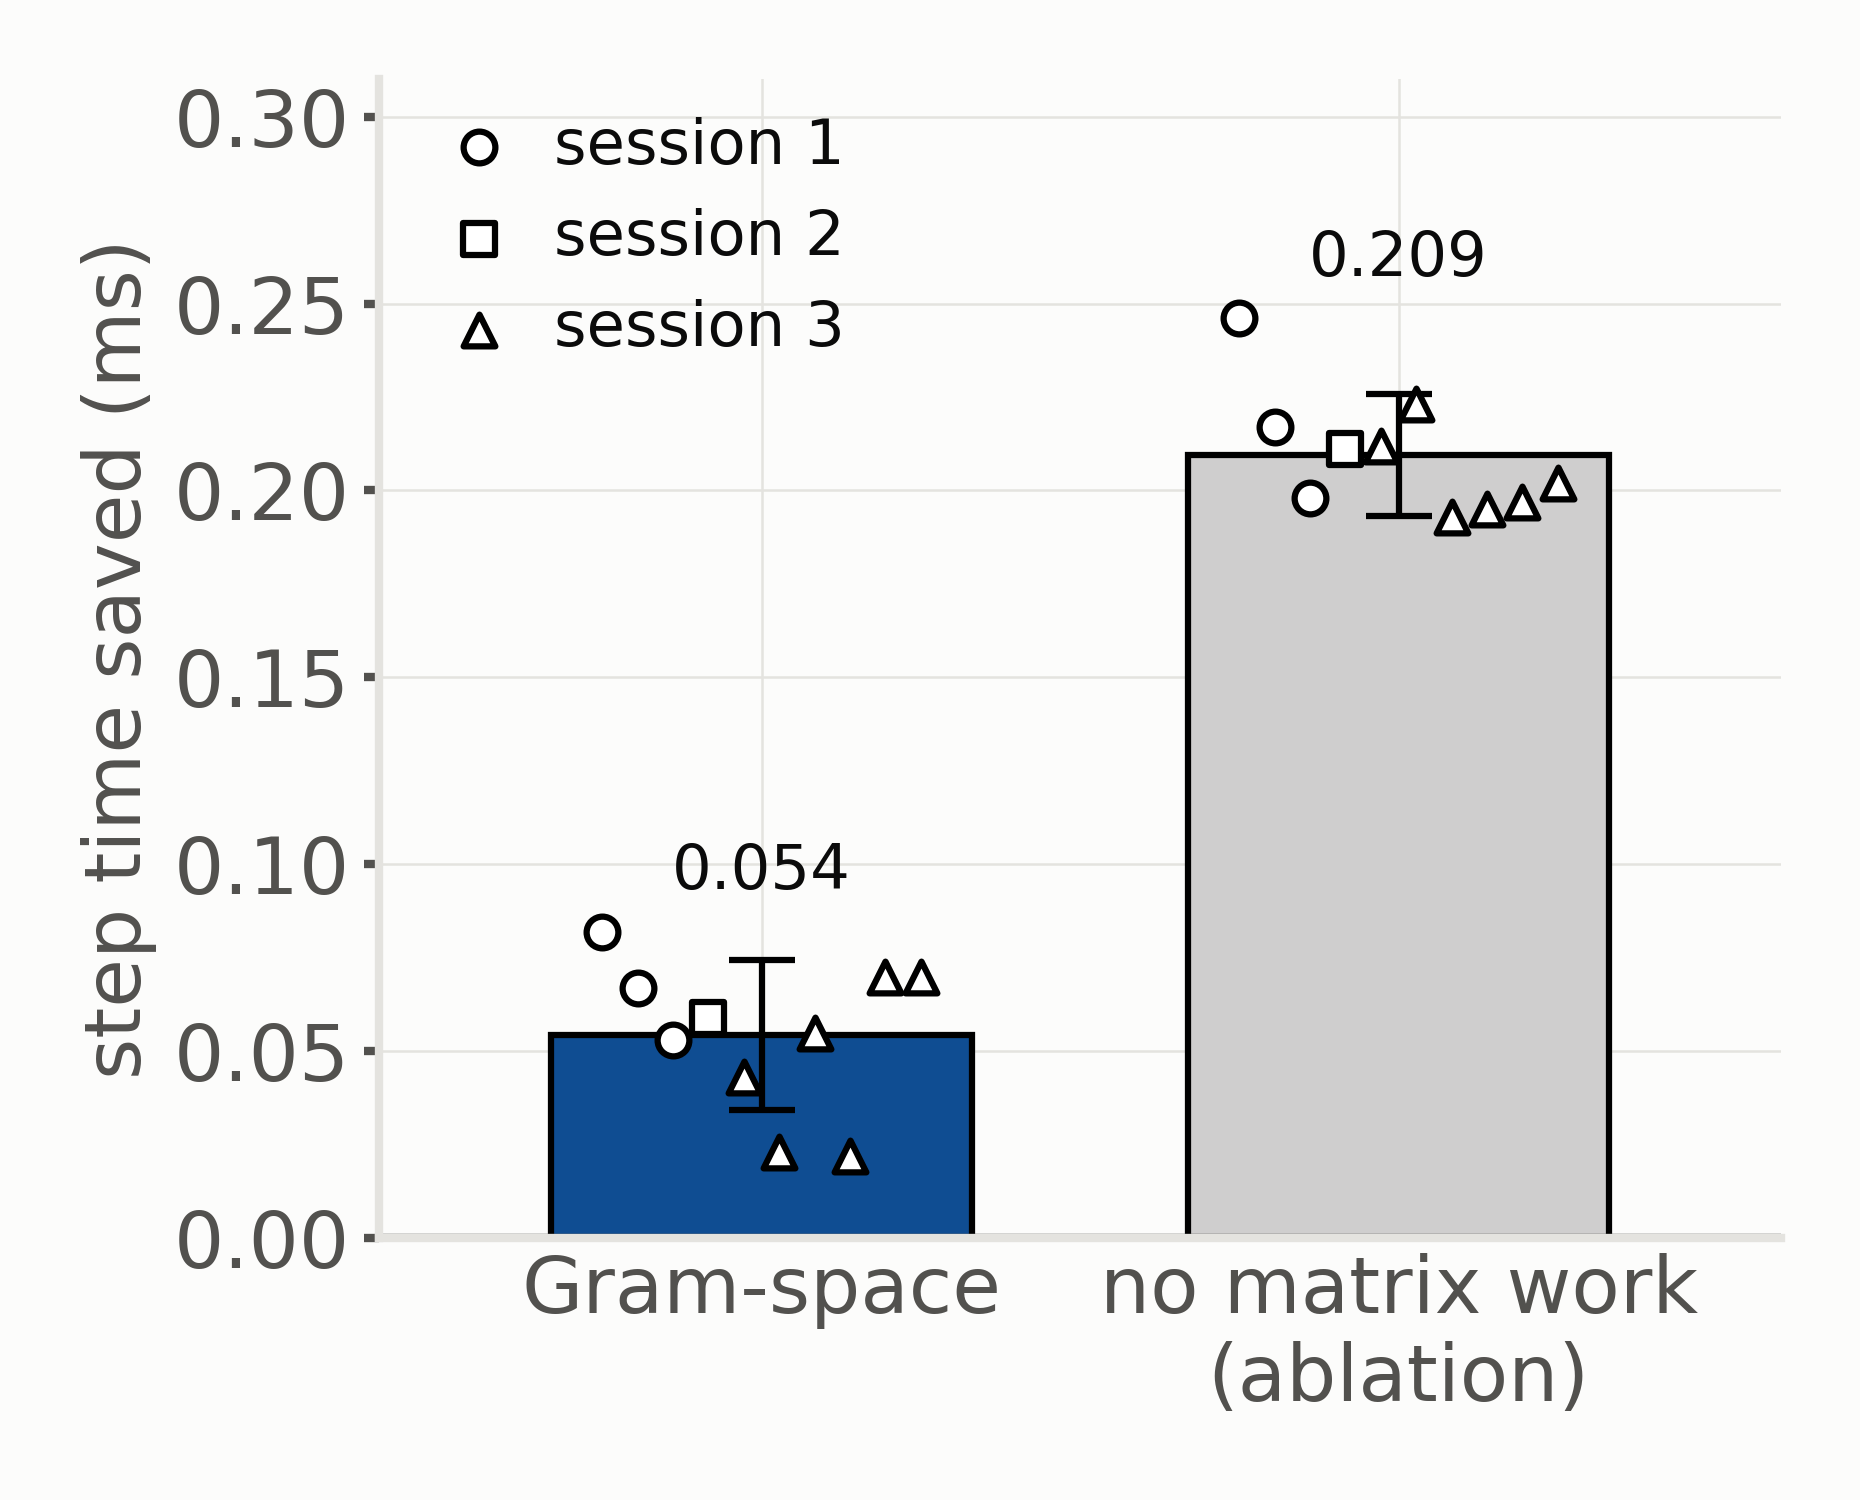

### fig_curve.png
Three seeds (5–7), mean ± sample SD. Training objective is rank-0 loss divided by tokens, includes changing auxiliary terms, and is not validation cross-entropy. Training y-axis is log; validation/differences are linear.

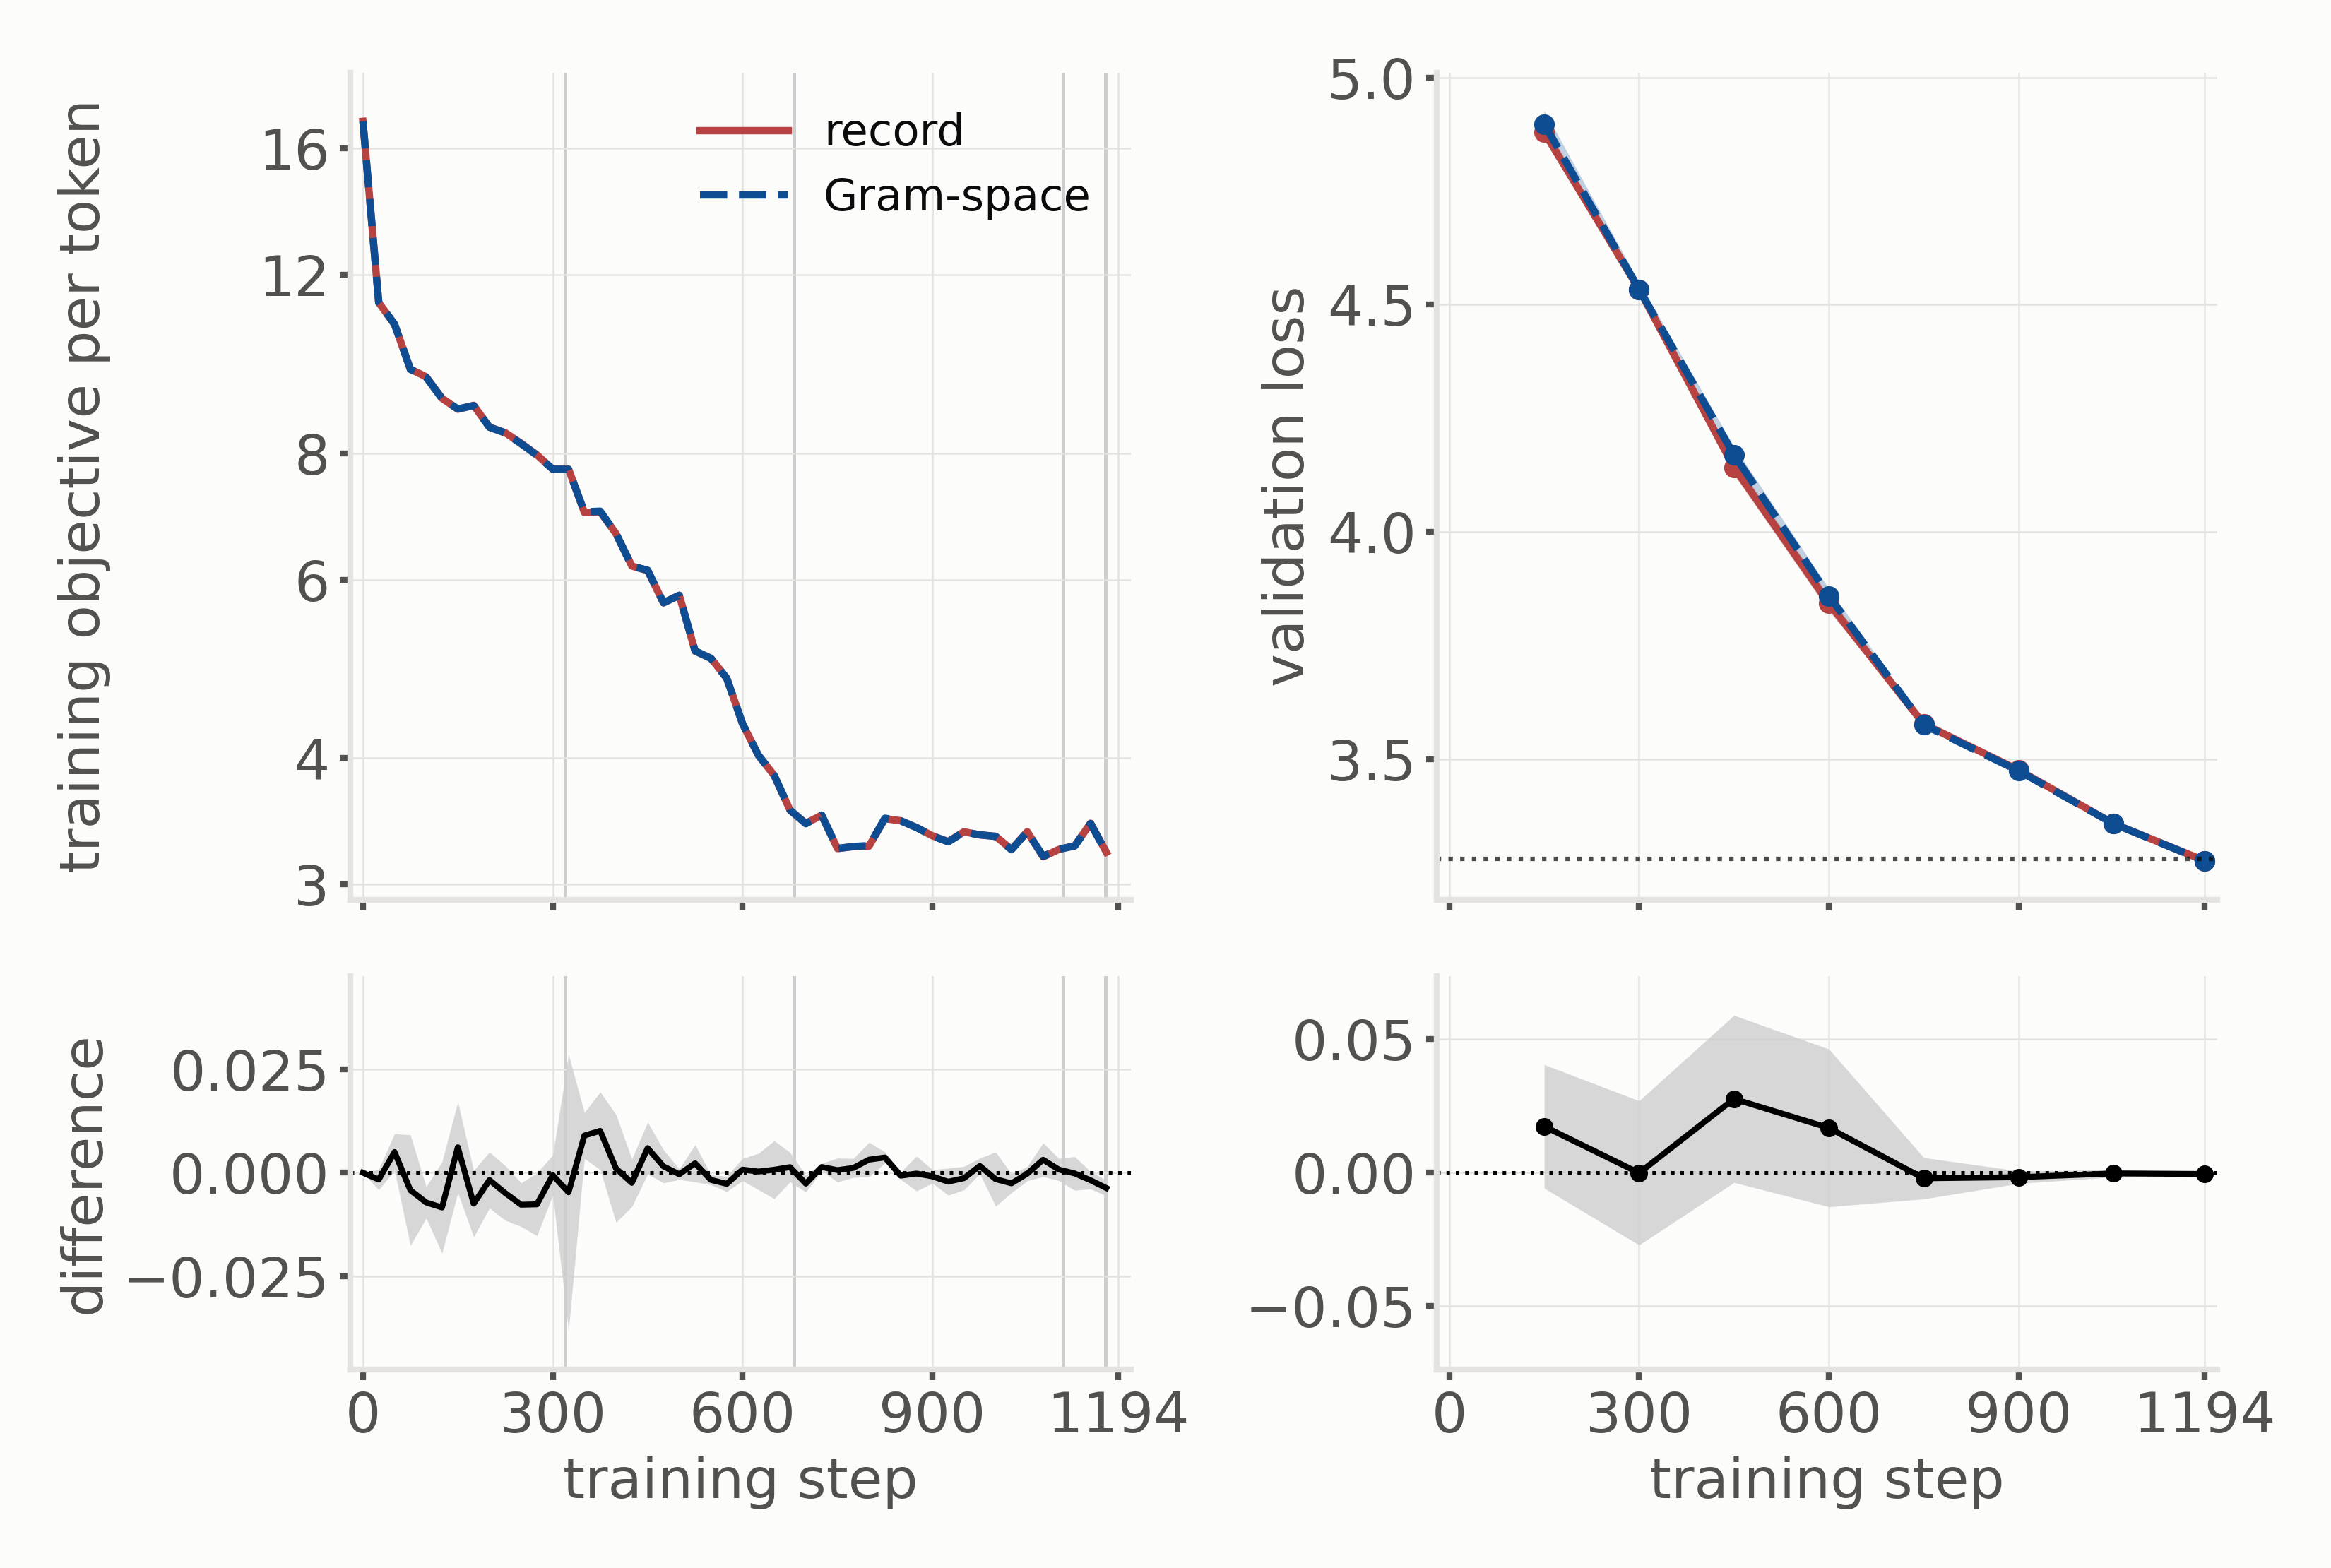

### fig_sweep.png
Shape sweep: measured speedup over the record. Left x-axis is log base 2; horizontal line is parity.

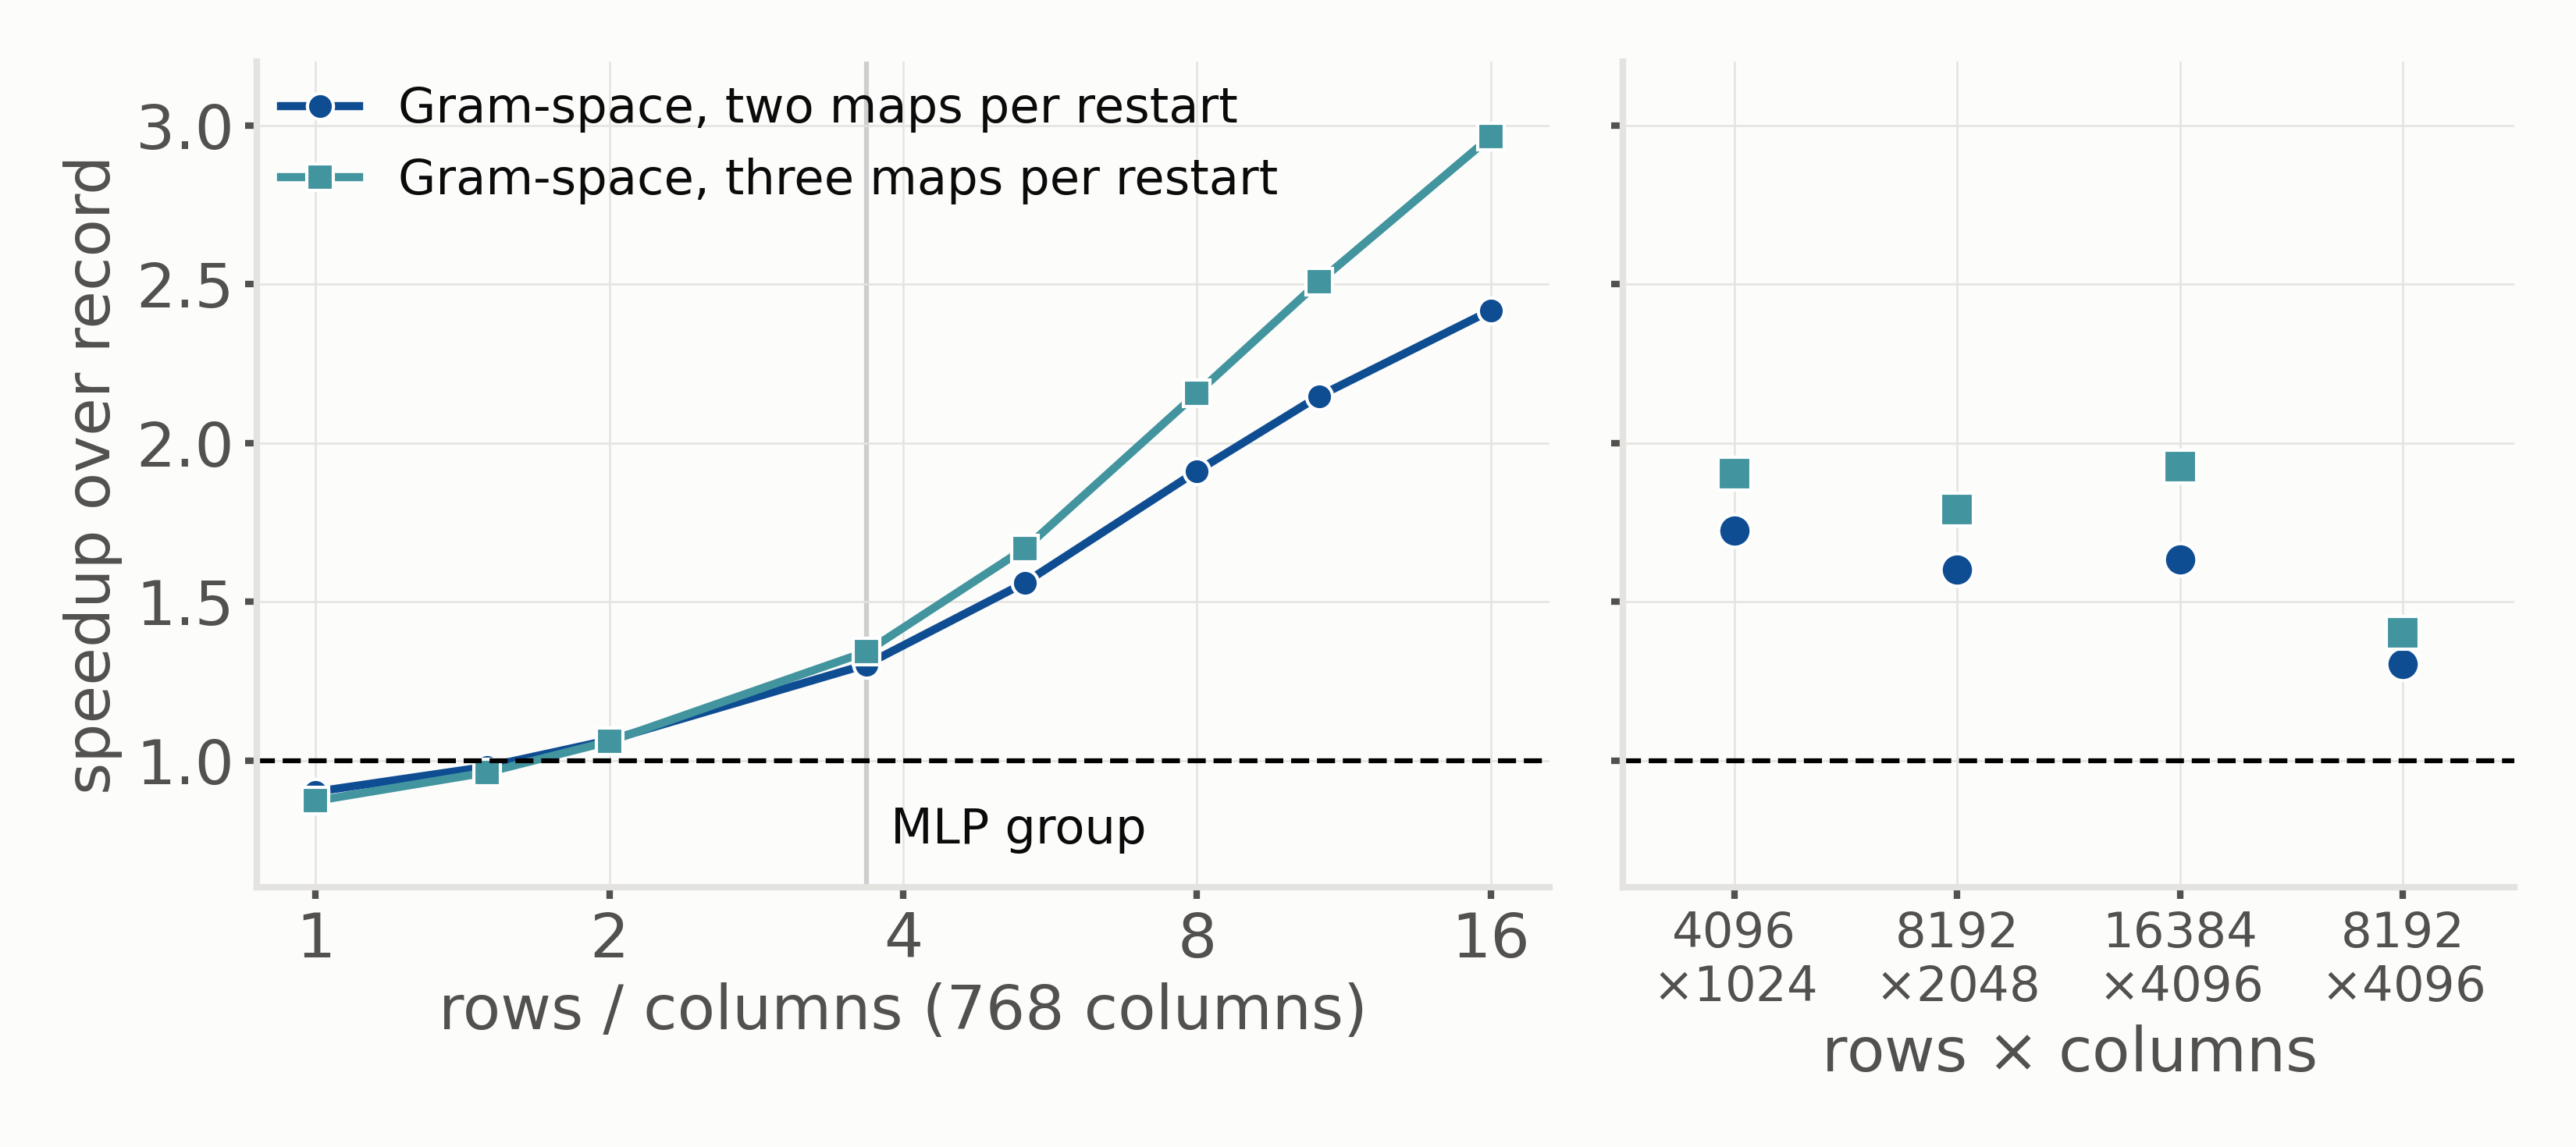

### fig_profile_late.png
Late rank-0 profile from archived analysis.txt; kernel categories can overlap across streams.

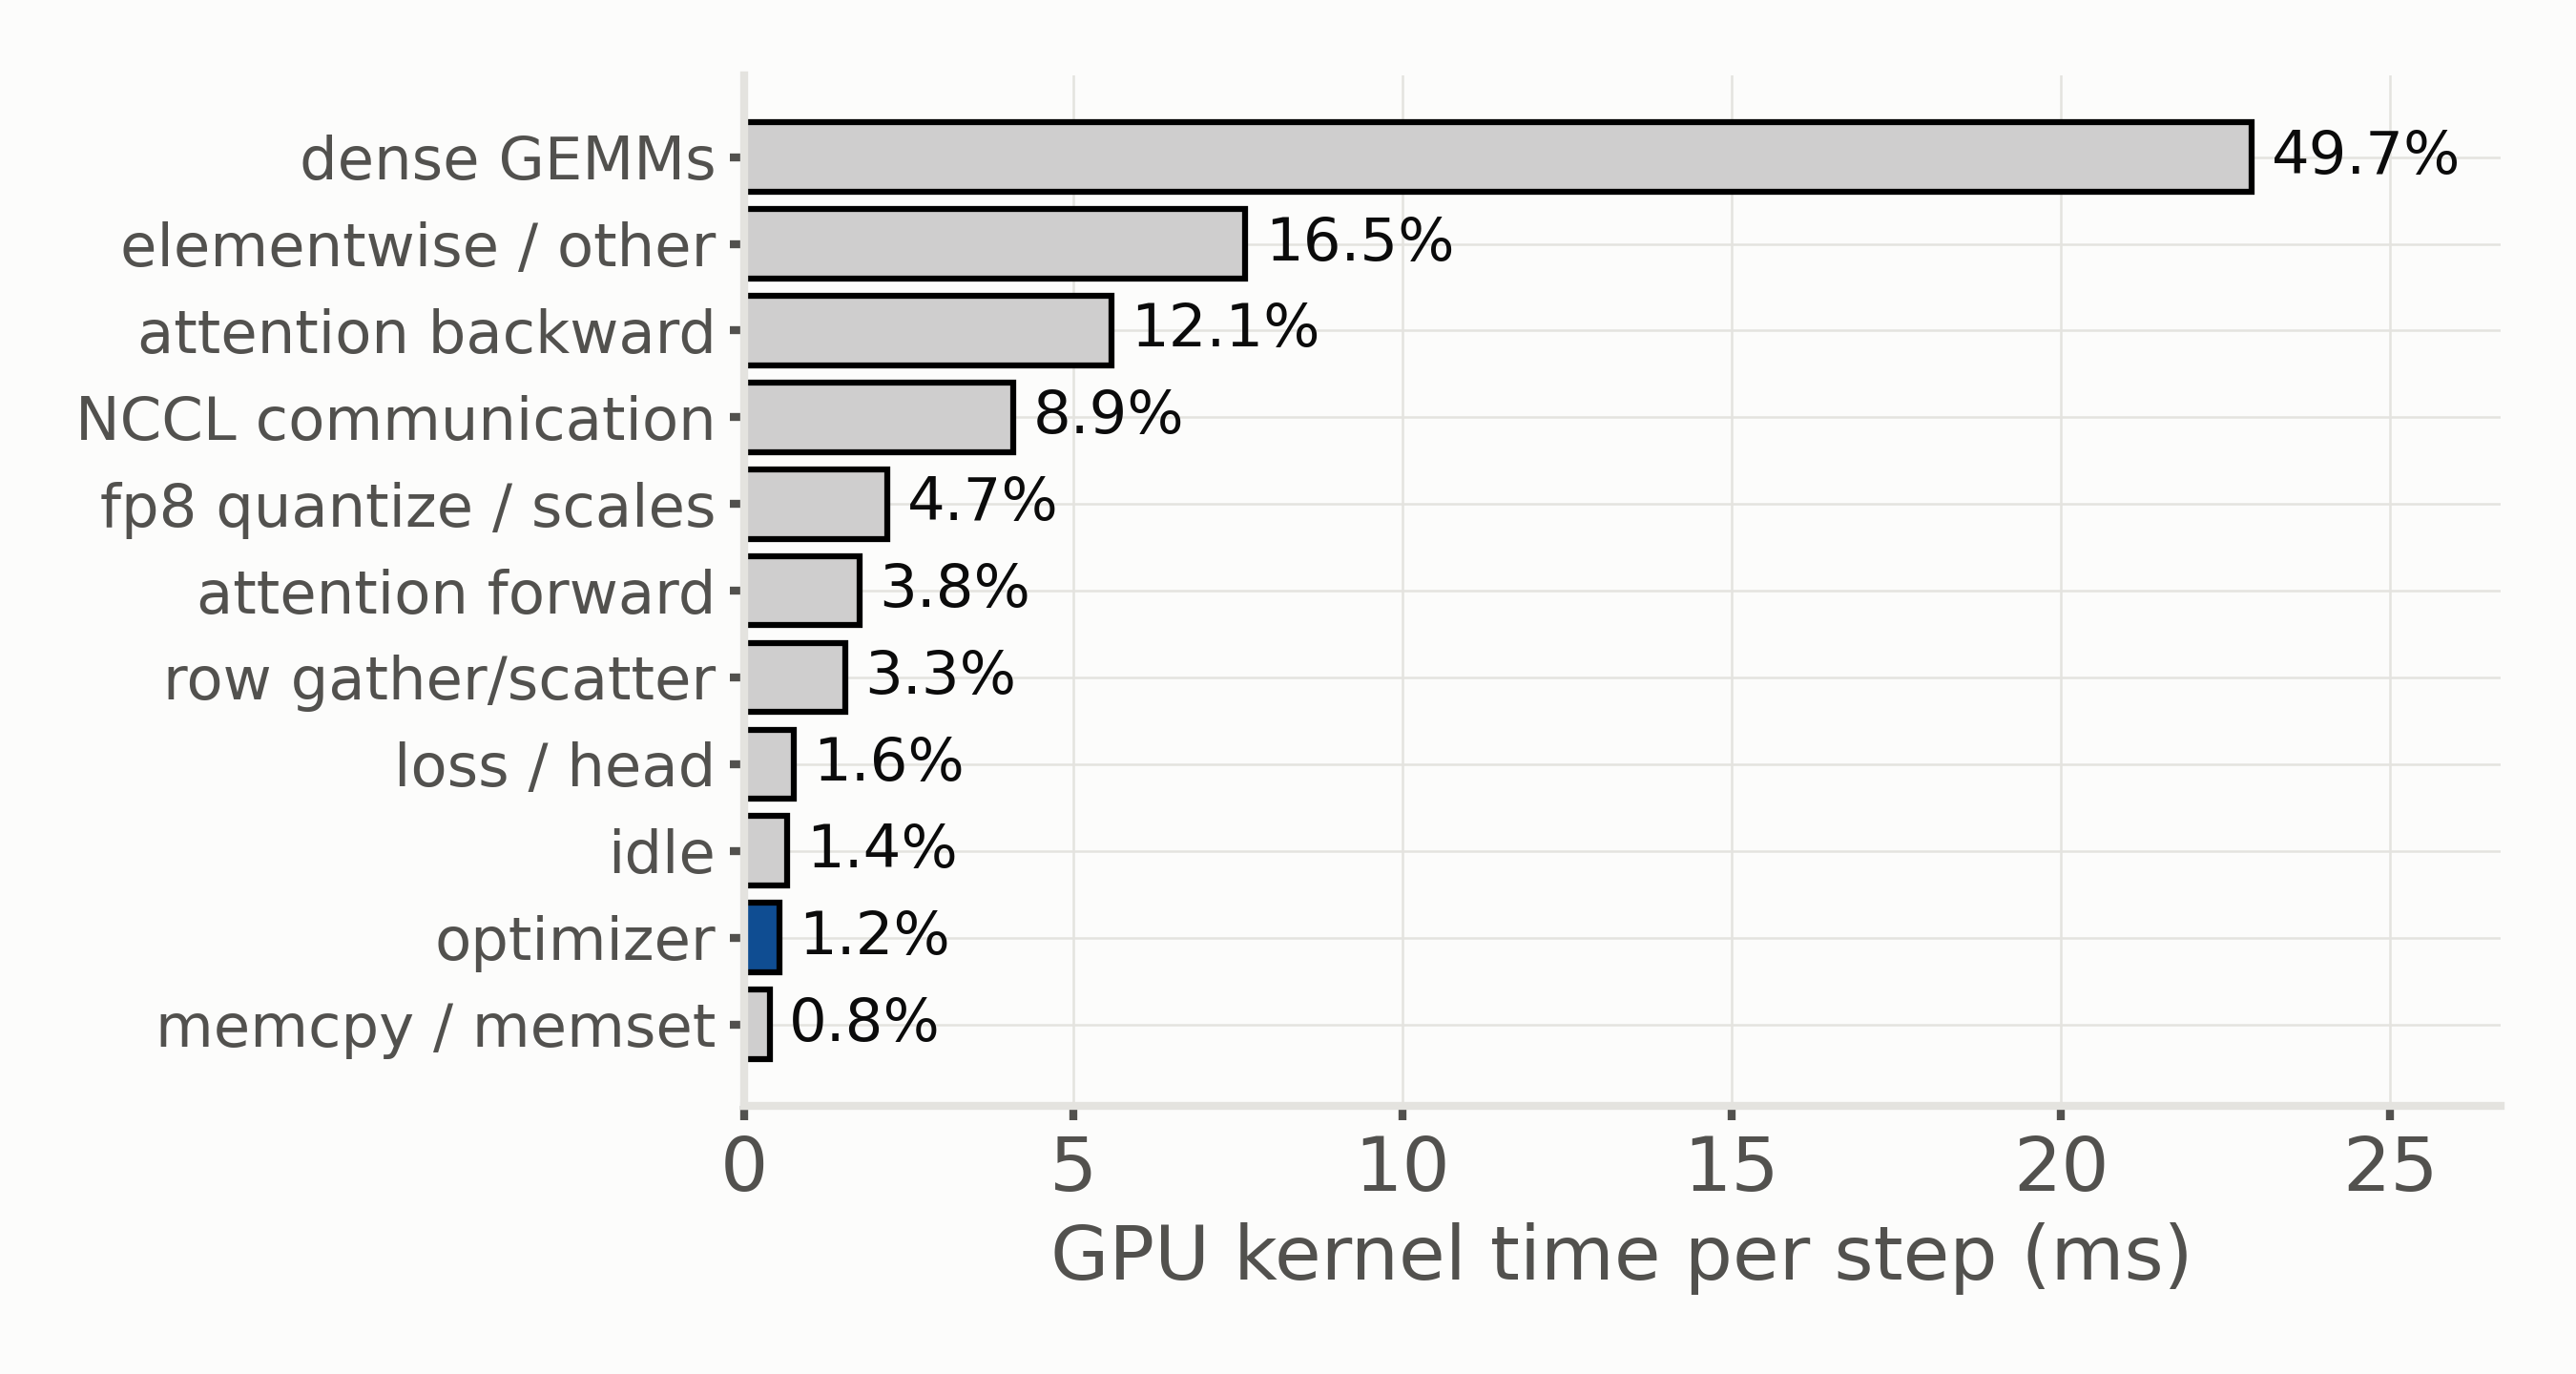

In [3]:
for filename, caption in runner.FIGURES.items():
    display(Markdown(f"### {filename}\n{caption}"))
    display(Image(filename=str(output / "paper" / filename), width=900))

## Tables and source traceability

`runs.csv` includes the raw-log path for each run. The full generated tables below retain historical/exploratory results as well as the main study: do not attribute upstream variant results to the team's kernel. These tables are not automatically inserted into LaTeX.

In [4]:
display(Markdown((output / "results/tables.md").read_text(encoding="utf-8")))

# Summary tables

Generated by `make_tables.py` from `raw/`. Do not edit: rerun the script. Times are the trainers' own
`train_time` (seconds). Val losses are printed as logged; means of losses are computed from those values.
sd is the sample standard deviation (n-1), se = sd/sqrt(n), CIs and p-values use Student's t.

## A. Each tree on our node (all valid runs, default flags)

| tree / config | runs | mean time (s) | sd | min | max | mean val loss | sd | worst val loss | runs at or under target | peak GPU mem allocated (MiB) | loop ms/step | METRIC mean step (ms) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| root record #92, baseline | 4 | 40.591 | 0.065 | 40.531 | 40.683 | 3.27609 | 0.00066 | 3.276999 | 4 | 48413 | 33.667 | 33.544 |
| root, ANVIL_KERNEL=gram222s (ours) | 4 | 40.511 | 0.018 | 40.496 | 40.535 | 3.27553 | 0.00074 | 3.276415 | 4 | 48413 | 33.595 | 33.445 |
| t1-gpu-stack (upstream PR #397 tree) | 2 | 30.719 | 0.000 | 30.719 | 30.719 | 3.27692 | 0.00028 | 3.277120 | 2 | 34310 | 28.802 | - |
| t1-cpu-ngram, 675 scheduled steps (upstream PR #381), all runs | 17 | 10.170 | 0.321 | 9.798 | 10.711 | 3.27526 | 0.00173 | 3.2778 | 17 | 49531 | 13.544 | - |
| t1-cpu-ngram, 675, without each job's first run | 12 | 10.000 | 0.200 | 9.798 | 10.522 | 3.27483 | 0.00180 | 3.2778 | 12 | 49531 | 13.538 | - |
| t1-cpu-ngram, 668 scheduled steps (our trim), all runs | 11 | 9.914 | 0.156 | 9.717 | 10.170 | 3.27688 | 0.00146 | 3.2800 | 11 | 49531 | 13.553 | - |
| t1-cpu-ngram, 668, interleaved-pair runs only | 8 | 9.828 | 0.060 | 9.717 | 9.925 | 3.27727 | 0.00146 | 3.2800 | 8 | 49531 | 13.545 | - |
| t2-cpu-ngram (Track 2, target 2.92) | 1 | 221.988 | - | 221.988 | 221.988 | 2.87856 | - | 2.878556 | 1 | 50482 | 38.132 | - |

`loop ms/step` = training clock at the last step (before the final validation) / steps, available for every tree.
`METRIC mean step` = mean of per-step latencies from `METRIC step_latency scope=all` (root tree with RUN_METRICS=1 only;
it leaves out step 0). Peak memory: root rows are
`METRIC peak_mem rank=max` (max over the 8 GPUs, timed loop); variant rows are the trainer's last line (rank 0).

## B. Optimizer kernel A/B on the root record (1194 steps)

### B1. Every run, in the order it ran

| job | order | start (UTC) | arm | seed | train time (s) | val loss | mean step (ms) | p95 step (ms) | peak alloc (MiB) | peak reserved (MiB) |
|---|---|---|---|---|---|---|---|---|---|---|
| bringup-1119 | 1 | 11-19T07:47:51 | base | 1 | 40.6828 | 3.275422 | 33.552 | 56.830 | 48413 | 62338 |
| bringup-1119 | 2 | 11-19T07:57:58 | skip_matrix | 1 | 40.2783 | 3.448960 | 33.306 | 56.643 | 48381 | 62774 |
| bringup-1119 | 3 | 11-19T08:04:25 | gram222s | 1 | 40.5149 | 3.274867 | 33.470 | 56.564 | 48413 | 62598 |
| bringup-1119 | 4 | 11-19T08:08:36 | base | 2 | 40.5660 | 3.276999 | 33.543 | 56.997 | 48413 | 62598 |
| bringup-1119 | 5 | 11-19T08:12:19 | gram222s | 2 | 40.4974 | 3.276415 | 33.476 | 59.119 | 48413 | 62598 |
| bringup-1119 | 6 | 11-19T08:16:03 | skip_matrix | 2 | 40.3254 | 3.451657 | 33.326 | 56.578 | 48381 | 62774 |
| bringup-1119 | 7 | 11-19T08:19:43 | base | 3 | 40.5309 | 3.276056 | 33.526 | 57.219 | 48413 | 62598 |
| bringup-1119 | 8 | 11-19T08:23:26 | gram222s | 3 | 40.5346 | 3.274970 | 33.473 | 57.823 | 48413 | 62598 |
| bringup-1119 | 9 | 11-19T08:27:05 | skip_matrix | 3 | 40.3744 | 3.462739 | 33.328 | 56.704 | 48381 | 62774 |
| bringup-1119 | 10 | 11-19T08:30:46 | base | 4 | 40.5843 | 3.275874 | 33.553 | 56.811 | 48413 | 62598 |
| fastest-1-1119-094724 | 7 | 11-19T18:40:25 | gram222s | 4 | 40.4962 | 3.275853 | 33.363 | 56.544 | 48413 | 62560 |
| fastest-1-1119-094724 | 8 | 11-19T18:45:38 | skip_matrix | 4 | 40.3003 | 3.457042 | 33.215 | 56.386 | 48381 | 62738 |

### B2. By arm

| arm | n | train time by seed 1-4 (s) | mean (s) | sd | val loss by seed 1-4 | mean val loss | sd | mean step (ms) |
|---|---|---|---|---|---|---|---|---|
| base | 4 | 40.6828 / 40.5660 / 40.5309 / 40.5843 | 40.5910 | 0.0651 | 3.275422 / 3.276999 / 3.276056 / 3.275874 | 3.276088 | 0.000663 | 33.544 |
| gram222s | 4 | 40.5149 / 40.4974 / 40.5346 / 40.4962 | 40.5108 | 0.0180 | 3.274867 / 3.276415 / 3.274970 / 3.275853 | 3.275526 | 0.000740 | 33.445 |
| skip_matrix | 4 | 40.2783 / 40.3254 / 40.3744 / 40.3003 | 40.3196 | 0.0413 | 3.448960 / 3.451657 / 3.462739 / 3.457042 | 3.455100 | 0.006101 | 33.294 |

### B2b. Second session (job kernel-ab2, another node; order swapped between seeds)

| order | arm | seed | train time (s) | val loss | mean step (ms) |
|---|---|---|---|---|---|
| 3 | gram222s | 6 | 40.4851 | 3.276890 | 33.387 |
| 4 | base | 6 | 40.4479 | 3.277197 | 33.446 |
| 5 | base | 7 | 40.4353 | 3.276937 | 33.442 |
| 6 | gram222s | 7 | 40.3800 | 3.276107 | 33.379 |
| 7 | skip_matrix | 6 | 40.1823 | 3.453502 | 33.235 |


Paired difference in mean step time (ms), same seed, both sessions:

| difference | pairs | by seed | mean (ms) | sd | se | t | s per run (x 1193 steps) |
|---|---|---|---|---|---|---|---|
| gram222s - base | 5 | -0.082 (s1) / -0.067 (s2) / -0.053 (s3) / -0.059 (s6) / -0.063 (s7) | -0.0648 | 0.0109 | 0.0049 | -13.27 | -0.077 |
| skip_matrix - base | 4 | -0.246 (s1) / -0.217 (s2) / -0.198 (s3) / -0.211 (s6) | -0.2180 | 0.0203 | 0.0101 | -21.50 | -0.260 |


### B2c. Third session (Slurm job qlabs-13354, one node; arm order rotated over seeds 8-13) and all sessions together

Convention in B2c: a **saving** is the record (base) minus the arm at the same seed in the same session, so a faster arm is
positive (B2b and B3 print arm - base, the opposite sign). Loss differences are arm - base. `mean step` is
`METRIC step_latency ... mean_ms` (the 1193 steps after step 0; printed to 0.001 ms). Out-of-loop time = step 0 + the tail
after the last step (`METRIC clock_split step0_ms + tail_ms`; for the first session, which has no clock_split line,
train time - mean step x 1193). Whole-run train time = step loop + out-of-loop time.

Per seed; each cell is base / gram222s / skip_matrix:

| seed | order the arms ran in | train time (s) | mean step (ms) | out-of-loop time (s) | val loss |
|---|---|---|---|---|---|
| 8 | base > gram222s > skip_matrix | 40.4294 / 40.3441 / 40.0806 | 33.354 / 33.311 / 33.142 | 0.638 / 0.605 / 0.543 | 3.276462 / 3.274850 / 3.464363 |
| 9 | gram222s > skip_matrix > base | 40.3426 / 40.3169 / 40.0934 | 33.369 / 33.346 / 33.146 | 0.533 / 0.535 / 0.550 | 3.278008 / 3.278722 / 3.475038 |
| 10 | skip_matrix > base > gram222s | 40.4065 / 40.2919 / 40.1156 | 33.357 / 33.302 / 33.164 | 0.612 / 0.562 / 0.550 | 3.277603 / 3.277020 / 3.454519 |
| 11 | base > skip_matrix > gram222s | 40.3078 / 40.3380 / 40.0957 | 33.342 / 33.320 / 33.147 | 0.530 / 0.588 / 0.552 | 3.279324 / 3.277545 / 3.457217 |
| 12 | gram222s > base > skip_matrix | 40.3346 / 40.3173 / 40.1205 | 33.369 / 33.299 / 33.172 | 0.525 / 0.591 / 0.547 | 3.275951 / 3.275851 / 3.453524 |
| 13 | skip_matrix > gram222s > base | 40.3568 / 40.2961 / 40.0871 | 33.371 / 33.301 / 33.169 | 0.545 / 0.568 / 0.516 | 3.277724 / 3.276626 / 3.450828 |

Warm-up run before these (seed 99, base, order 7 in the job): train time 40.3653 s, mean step 33.343 ms, val loss 3.275864. It is in runs.csv with role=warmup and is not used in any statistic.

Unpaired, by arm (mean ± sd over seeds 8-13):

| arm | n | train time (s) | step loop (s) | mean step (ms) | out-of-loop time (s) | out-of-loop range (s) | val loss |
|---|---|---|---|---|---|---|---|
| base | 6 | 40.3630 ± 0.0461 | 39.7989 ± 0.0136 | 33.3603 ± 0.0114 | 0.5638 ± 0.0484 | 0.525 - 0.638 | 3.277512 ± 0.001193 |
| gram222s | 6 | 40.3174 ± 0.0212 | 39.7426 ± 0.0214 | 33.3132 ± 0.0179 | 0.5748 ± 0.0249 | 0.535 - 0.605 | 3.276769 ± 0.001344 |
| skip_matrix | 6 | 40.0988 ± 0.0159 | 39.5559 ± 0.0157 | 33.1567 ± 0.0131 | 0.5430 ± 0.0136 | 0.516 - 0.552 | 3.459248 ± 0.009007 |

Out-of-loop time over all 18 runs: 0.516 to 0.638 s (mean 0.561, sd 0.033); step 0 126.6 to 208.9 ms (mean 148.4), tail 389.5 to 490.0 ms (mean 412.1).

Paired savings against the record, this session only (seeds 8, 9, 10, 11, 12, 13):

| arm | saving (base - arm) | by seed | n | mean | sd | se | t | p (two-sided) |
|---|---|---|---|---|---|---|---|---|
| gram222s | mean step, all 1193 steps (ms) | +0.043 / +0.023 / +0.055 / +0.022 / +0.070 / +0.070 | 6 | +0.0472 | 0.0216 | 0.0088 | 5.34 | 0.0031 |
| gram222s | mean step, stage0 (319 steps) (ms) | +0.056 / +0.044 / +0.043 / +0.035 / +0.051 / +0.049 | 6 | +0.0463 | 0.0073 | 0.0030 | 15.52 | 2.0e-05 |
| gram222s | mean step, stage1 (361 steps) (ms) | +0.032 / +0.036 / +0.063 / +0.041 / +0.049 / +0.059 | 6 | +0.0467 | 0.0125 | 0.0051 | 9.12 | 0.0003 |
| gram222s | mean step, stage2 (426 steps) (ms) | +0.039 / +0.004 / +0.045 / +0.003 / +0.106 / +0.088 | 6 | +0.0475 | 0.0425 | 0.0173 | 2.74 | 0.0408 |
| gram222s | mean step, stage3 (67 steps) (ms) | +0.073 / -0.045 / +0.112 / +0.024 / +0.047 / +0.117 | 6 | +0.0547 | 0.0607 | 0.0248 | 2.20 | 0.0786 |
| gram222s | mean step, stage4 (20 steps) (ms) | +0.051 / +0.108 / +0.111 / -0.059 / +0.062 / +0.063 | 6 | +0.0560 | 0.0617 | 0.0252 | 2.22 | 0.0770 |
| gram222s | train time, whole run (s) | +0.085 / +0.026 / +0.115 / -0.030 / +0.017 / +0.061 | 6 | +0.0456 | 0.0520 | 0.0212 | 2.15 | 0.0845 |
| gram222s | out-of-loop time (s) | +0.033 / -0.002 / +0.050 / -0.058 / -0.066 / -0.023 | 6 | -0.0110 | 0.0470 | 0.0192 | -0.57 | 0.5915 |
| skip_matrix | mean step, all 1193 steps (ms) | +0.212 / +0.223 / +0.193 / +0.195 / +0.197 / +0.202 | 6 | +0.2037 | 0.0117 | 0.0048 | 42.80 | <1e-6 |
| skip_matrix | mean step, stage0 (319 steps) (ms) | +0.179 / +0.163 / +0.163 / +0.169 / +0.170 / +0.169 | 6 | +0.1688 | 0.0059 | 0.0024 | 70.34 | <1e-6 |
| skip_matrix | mean step, stage1 (361 steps) (ms) | +0.218 / +0.224 / +0.199 / +0.210 / +0.180 / +0.209 | 6 | +0.2067 | 0.0156 | 0.0064 | 32.47 | <1e-6 |
| skip_matrix | mean step, stage2 (426 steps) (ms) | +0.223 / +0.270 / +0.200 / +0.200 / +0.231 / +0.220 | 6 | +0.2240 | 0.0258 | 0.0105 | 21.25 | 4.3e-06 |
| skip_matrix | mean step, stage3 (67 steps) (ms) | +0.287 / +0.198 / +0.260 / +0.229 / +0.215 / +0.210 | 6 | +0.2332 | 0.0339 | 0.0138 | 16.86 | 1.3e-05 |
| skip_matrix | mean step, stage4 (20 steps) (ms) | +0.167 / +0.274 / +0.168 / +0.186 / +0.170 / +0.193 | 6 | +0.1930 | 0.0411 | 0.0168 | 11.51 | 8.7e-05 |
| skip_matrix | train time, whole run (s) | +0.349 / +0.249 / +0.291 / +0.212 / +0.214 / +0.270 | 6 | +0.2641 | 0.0517 | 0.0211 | 12.52 | 5.8e-05 |
| skip_matrix | out-of-loop time (s) | +0.095 / -0.017 / +0.061 / -0.022 / -0.021 / +0.029 | 6 | +0.0209 | 0.0496 | 0.0202 | 1.03 | 0.3499 |

Paired difference in final val loss, this session (the skip_matrix arm is not a valid training run):

| difference | by seed | n | mean | sd | se | t | p (two-sided) |
|---|---|---|---|---|---|---|---|
| gram222s - base | -0.001612 / +0.000714 / -0.000583 / -0.001779 / -0.000100 / -0.001098 | 6 | -0.000743 | 0.000950 | 0.000388 | -1.91 | 0.1137 |
| skip_matrix - base | +0.187901 / +0.197030 / +0.176916 / +0.177893 / +0.177573 / +0.173104 | 6 | +0.181736 | 0.008964 | 0.003659 | 49.66 | <1e-6 |

#### All sessions, the same 10 seeds for both arms (1, 2, 3, 6, 8, 9, 10, 11, 12, 13)

Seed 4 is left out because its arms ran on different nodes; seed 7 because it has no ablation run (its kernel pair is shown
separately below); seed 5 has curve runs only. Sessions: 1 = bring-up node (seeds 1-3, record first), 2 = job kernel-ab2 (seed 6),
3 = job qlabs-13354 (seeds 8-13, order rotated). `s per run` = saving per step x that scope's steps; `% of run` is against the
record's mean train time over these seeds, 40.4405 s (sd 0.1199).

| arm | saving (base - arm) | n | mean | sd | se | t | p (two-sided) | s per run | % of run |
|---|---|---|---|---|---|---|---|---|---|
| gram222s | mean step, all 1193 steps (ms) | 10 | +0.0544 | 0.0200 | 0.0063 | 8.61 | 1.2e-05 | +0.0649 | +0.160% |
| gram222s | mean step, stage0 (319 steps) (ms) | 10 | +0.0430 | 0.0075 | 0.0024 | 18.03 | <1e-6 | +0.0137 | +0.034% |
| gram222s | mean step, stage1 (361 steps) (ms) | 10 | +0.0578 | 0.0246 | 0.0078 | 7.44 | 3.9e-05 | +0.0209 | +0.052% |
| gram222s | mean step, stage2 (426 steps) (ms) | 10 | +0.0628 | 0.0382 | 0.0121 | 5.20 | 0.0006 | +0.0268 | +0.066% |
| gram222s | mean step, stage3 (67 steps) (ms) | 10 | +0.0435 | 0.0523 | 0.0165 | 2.63 | 0.0274 | +0.0029 | +0.007% |
| gram222s | mean step, stage4 (20 steps) (ms) | 10 | +0.0353 | 0.0660 | 0.0209 | 1.69 | 0.1251 | +0.0007 | +0.002% |
| gram222s | train time, whole run (s) | 10 | +0.0469 | 0.0652 | 0.0206 | 2.27 | 0.0490 | +0.0469 | +0.116% |
| gram222s | out-of-loop time (s) | 10 | -0.0181 | 0.0571 | 0.0181 | -1.00 | 0.3435 | -0.0181 | -0.045% |
| skip_matrix | mean step, all 1193 steps (ms) | 10 | +0.2094 | 0.0164 | 0.0052 | 40.50 | <1e-6 | +0.2498 | +0.618% |
| skip_matrix | mean step, stage0 (319 steps) (ms) | 10 | +0.1683 | 0.0063 | 0.0020 | 84.37 | <1e-6 | +0.0537 | +0.133% |
| skip_matrix | mean step, stage1 (361 steps) (ms) | 10 | +0.2089 | 0.0260 | 0.0082 | 25.39 | <1e-6 | +0.0754 | +0.186% |
| skip_matrix | mean step, stage2 (426 steps) (ms) | 10 | +0.2402 | 0.0330 | 0.0104 | 23.00 | <1e-6 | +0.1023 | +0.253% |
| skip_matrix | mean step, stage3 (67 steps) (ms) | 10 | +0.2180 | 0.0423 | 0.0134 | 16.28 | <1e-6 | +0.0146 | +0.036% |
| skip_matrix | mean step, stage4 (20 steps) (ms) | 10 | +0.1967 | 0.0560 | 0.0177 | 11.11 | 1.5e-06 | +0.0039 | +0.010% |
| skip_matrix | train time, whole run (s) | 10 | +0.2652 | 0.0709 | 0.0224 | 11.84 | <1e-6 | +0.2652 | +0.656% |
| skip_matrix | out-of-loop time (s) | 10 | +0.0153 | 0.0594 | 0.0188 | 0.81 | 0.4376 | +0.0153 | +0.038% |

By session (one pair has no sd):

| arm | session | step: n | step: mean | step: sd | step: se | step: t | step: p (two-sided) | step: s per run (x 1193) | train time (s): mean | train time (s): sd | train time (s): se | train time (s): t | train time (s): p (two-sided) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| gram222s | 1 (seeds 1-3) | 3 | +0.0673 | 0.0145 | 0.0084 | 8.04 | 0.0151 | +0.0803 | +0.0776 | 0.0862 | 0.0497 | 1.56 | 0.2591 |
| gram222s | 2 (seed 6) | 1 | +0.0590 | - | - | - | - | +0.0704 | -0.0372 | - | - | - | - |
| gram222s | 3 (seeds 8-13) | 6 | +0.0472 | 0.0216 | 0.0088 | 5.34 | 0.0031 | +0.0563 | +0.0456 | 0.0520 | 0.0212 | 2.15 | 0.0845 |
| gram222s | all three (10 seeds) | 10 | +0.0544 | 0.0200 | 0.0063 | 8.61 | 1.2e-05 | +0.0649 | +0.0469 | 0.0652 | 0.0206 | 2.27 | 0.0490 |
| gram222s | all three + seed 7 (kernel only; not the common-seed set) | 11 | +0.0552 | 0.0191 | 0.0058 | 9.56 | 2.4e-06 | +0.0658 | +0.0477 | 0.0619 | 0.0187 | 2.55 | 0.0287 |
| skip_matrix | 1 (seeds 1-3) | 3 | +0.2203 | 0.0242 | 0.0140 | 15.79 | 0.0040 | +0.2629 | +0.2672 | 0.1261 | 0.0728 | 3.67 | 0.0669 |
| skip_matrix | 2 (seed 6) | 1 | +0.2110 | - | - | - | - | +0.2517 | +0.2656 | - | - | - | - |
| skip_matrix | 3 (seeds 8-13) | 6 | +0.2037 | 0.0117 | 0.0048 | 42.80 | <1e-6 | +0.2430 | +0.2641 | 0.0517 | 0.0211 | 12.52 | 5.8e-05 |
| skip_matrix | all three (10 seeds) | 10 | +0.2094 | 0.0164 | 0.0052 | 40.50 | <1e-6 | +0.2498 | +0.2652 | 0.0709 | 0.0224 | 11.84 | <1e-6 |

The pairs behind these rows (savings, base - arm):

| seed | session | gram222s: mean step (ms) | skip_matrix: mean step (ms) | gram222s: train time (s) | skip_matrix: train time (s) | gram222s: out-of-loop (s) | skip_matrix: out-of-loop (s) |
|---|---|---|---|---|---|---|---|
| 1 | 1 | +0.082 | +0.246 | +0.168 | +0.404 | +0.070 | +0.111 |
| 2 | 1 | +0.067 | +0.217 | +0.069 | +0.241 | -0.011 | -0.018 |
| 3 | 1 | +0.053 | +0.198 | -0.004 | +0.157 | -0.067 | -0.080 |
| 6 | 2 | +0.059 | +0.211 | -0.037 | +0.266 | -0.106 | +0.014 |
| 8 | 3 | +0.043 | +0.212 | +0.085 | +0.349 | +0.033 | +0.095 |
| 9 | 3 | +0.023 | +0.223 | +0.026 | +0.249 | -0.002 | -0.017 |
| 10 | 3 | +0.055 | +0.193 | +0.115 | +0.291 | +0.050 | +0.061 |
| 11 | 3 | +0.022 | +0.195 | -0.030 | +0.212 | -0.058 | -0.022 |
| 12 | 3 | +0.070 | +0.197 | +0.017 | +0.214 | -0.066 | -0.021 |
| 13 | 3 | +0.070 | +0.202 | +0.061 | +0.270 | -0.023 | +0.029 |

#### Final validation loss, record vs kernel (timing runs; seed 4 is included here, its loss does not depend on the node's speed)

| seeds | n | record (mean ± sd) | gram222s (mean ± sd) | gram222s - record: mean | gram222s - record: sd | gram222s - record: se | gram222s - record: t | gram222s - record: p (two-sided) | pairs where the kernel is lower | worst run, record / gram222s |
|---|---|---|---|---|---|---|---|---|---|---|
| all valid timing seeds (1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 12, 13) | 12 | 3.276963 ± 0.001102 | 3.276310 ± 0.001159 | -0.000653 | 0.000695 | 0.000201 | -3.26 | 0.0077 | 11 of 12 | 3.279324 / 3.278722 |
| the 10 common seeds | 10 | 3.277075 ± 0.001158 | 3.276376 ± 0.001268 | -0.000699 | 0.000735 | 0.000233 | -3.01 | 0.0148 | 9 of 10 | 3.279324 / 3.278722 |
| third session (8, 9, 10, 11, 12, 13) | 6 | 3.277512 ± 0.001193 | 3.276769 ± 0.001344 | -0.000743 | 0.000950 | 0.000388 | -1.91 | 0.1137 | 5 of 6 | 3.279324 / 3.278722 |

#### Curve runs of the third session (experiment `curve3`; VAL_CURVE=150, TRAIN_LOSS_EVERY=25; never used for timing)

| order | arm | seed | final val loss | outcome |
|---|---|---|---|---|
| 1 | base | 5 | 3.273061 | finished, at or under 3.28 |
| 2 | gram222s | 5 | 3.273521 | finished, at or under 3.28 |
| 3 | gram222s | 6 | 3.276892 | finished, at or under 3.28 |
| 4 | base | 6 | 3.277917 | finished, at or under 3.28 |
| 5 | base | 7 | 3.276423 | finished, at or under 3.28 |
| 6 | gram222s | 7 | 3.275588 | finished, at or under 3.28 |
| 26 | gram33s | 5 | nan | DIVERGED: training loss is NaN from the step-400 read on (last finite read: step 375), validation loss is NaN from step 450 to the end |
| 27 | gram33s | 6 | 3.276379 | finished, at or under 3.28 |
| 28 | gram33s | 7 | 3.277907 | finished, at or under 3.28 |
| 29 | gram42s | 5 | - | FAILED before training (AssertionError: step graph StepGraphKey(tokens=32768, cu_seqlens_rows=96, mtp_targets=2, candidates=10240, ws_short=384, ws_long=896, max_seq_len=2048): replay loss nan != eager nan) |
| 30 | gram42s | 6 | - | FAILED before training (AssertionError: step graph StepGraphKey(tokens=49152, cu_seqlens_rows=128, mtp_targets=1, candidates=14336, ws_short=640, ws_long=1408, max_seq_len=2560): replay loss nan != eager nan) |

Validation loss by step, seeds 5, 6, 7 (mean ± sd over the 3 seeds; the difference is paired by seed):

| step | record | gram222s | gram222s - record | gram33s seed 5 | gram33s seed 6 | gram33s seed 7 |
|---|---|---|---|---|---|---|
| 150 | 4.88013 ± 0.01688 | 4.89749 ± 0.03007 | +0.01735 ± 0.02314 | 4.862928 | 4.916800 | 4.886074 |
| 300 | 4.53392 ± 0.01141 | 4.53384 ± 0.01569 | -0.00008 ± 0.02700 | 4.536472 | 4.522589 | 4.548343 |
| 450 | 4.14209 ± 0.01665 | 4.16974 ± 0.01802 | +0.02766 ± 0.03132 | nan | 4.176300 | 4.175006 |
| 600 | 3.84215 ± 0.01670 | 3.85892 ± 0.01581 | +0.01678 ± 0.02954 | nan | 3.842229 | 3.837338 |
| 750 | 3.57696 ± 0.00381 | 3.57487 ± 0.00657 | -0.00209 ± 0.00774 | nan | 3.579982 | 3.578476 |
| 900 | 3.47535 ± 0.00238 | 3.47368 ± 0.00294 | -0.00167 ± 0.00236 | nan | 3.484752 | 3.475650 |
| 1050 | 3.35762 ± 0.00242 | 3.35736 ± 0.00244 | -0.00026 ± 0.00135 | nan | 3.360538 | 3.359812 |
| 1194 | 3.27580 ± 0.00249 | 3.27533 ± 0.00170 | -0.00047 ± 0.00081 | nan | 3.276379 | 3.277907 |

Final val loss of the curve runs, gram222s - record by seed (5, 6, 7): +0.000460 / -0.001025 / -0.000835; mean -0.000467, se 0.000467, n = 3.

Training objective per token by step (same seeds, mean ± sd). `METRIC train loss=` is rank 0's training objective summed over
its tokens of that step (`step_graphs.py`: the per-token loss `.sum()`); it is divided here by the tokens per rank of the step's
stage (`config.py` batch_size / 8 ranks). The per-token objective is the weighted sum of the next-token CE, the multi-token
CE terms and the prefix-token CE, over a sampled candidate set of 10240 / 14336 / 24576 classes until step 1106 and the full
vocabulary after. Its weights and candidate count change with the schedule, so it is not a plain next-token cross-entropy and
is not comparable with the validation loss.

| step | stage | tokens per rank | record | gram222s | gram222s - record |
|---|---|---|---|---|---|
| 0 | 0 | 16384 | 17.0187 ± 0.0036 | 17.0187 ± 0.0036 | +0.0000 ± 0.0000 |
| 25 | 0 | 16384 | 11.2702 ± 0.0579 | 11.2686 ± 0.0575 | -0.0016 ± 0.0025 |
| 50 | 0 | 16384 | 10.7244 ± 0.0705 | 10.7294 ± 0.0744 | +0.0050 ± 0.0044 |
| 75 | 0 | 16384 | 9.6874 ± 0.0424 | 9.6832 ± 0.0351 | -0.0042 ± 0.0133 |
| 100 | 0 | 16384 | 9.5186 ± 0.0234 | 9.5114 ± 0.0208 | -0.0072 ± 0.0038 |
| 125 | 0 | 16384 | 9.0664 ± 0.0237 | 9.0581 ± 0.0241 | -0.0084 ± 0.0110 |
| 150 | 0 | 16384 | 8.8427 ± 0.0311 | 8.8488 ± 0.0227 | +0.0061 ± 0.0109 |
| 175 | 0 | 16384 | 8.9218 ± 0.0109 | 8.9143 ± 0.0079 | -0.0075 ± 0.0080 |
| 200 | 0 | 16384 | 8.4895 ± 0.0213 | 8.4877 ± 0.0151 | -0.0018 ± 0.0068 |
| 225 | 0 | 16384 | 8.3830 ± 0.0126 | 8.3781 ± 0.0158 | -0.0049 ± 0.0066 |
| 250 | 0 | 16384 | 8.1837 ± 0.0072 | 8.1760 ± 0.0038 | -0.0077 ± 0.0053 |
| 275 | 0 | 16384 | 7.9719 ± 0.0072 | 7.9642 ± 0.0091 | -0.0076 ± 0.0076 |
| 300 | 0 | 16384 | 7.7157 ± 0.0078 | 7.7151 ± 0.0053 | -0.0006 ± 0.0048 |
| 325 | 1 | 32768 | 7.7178 ± 0.0305 | 7.7131 ± 0.0564 | -0.0047 ± 0.0332 |
| 350 | 1 | 32768 | 6.9925 ± 0.0053 | 7.0015 ± 0.0051 | +0.0090 ± 0.0055 |
| 375 | 1 | 32768 | 7.0028 ± 0.0089 | 7.0129 ± 0.0011 | +0.0101 ± 0.0094 |
| 400 | 1 | 32768 | 6.6639 ± 0.0040 | 6.6650 ± 0.0147 | +0.0010 ± 0.0130 |
| 425 | 1 | 32768 | 6.1914 ± 0.0007 | 6.1890 ± 0.0052 | -0.0024 ± 0.0057 |
| 450 | 1 | 32768 | 6.1264 ± 0.0054 | 6.1323 ± 0.0056 | +0.0059 ± 0.0062 |
| 475 | 1 | 32768 | 5.6933 ± 0.0032 | 5.6948 ± 0.0030 | +0.0015 ± 0.0040 |
| 500 | 1 | 32768 | 5.7924 ± 0.0075 | 5.7920 ± 0.0065 | -0.0004 ± 0.0013 |
| 525 | 1 | 32768 | 5.1017 ± 0.0037 | 5.1040 ± 0.0020 | +0.0023 ± 0.0045 |
| 550 | 1 | 32768 | 5.0197 ± 0.0048 | 5.0180 ± 0.0042 | -0.0017 ± 0.0012 |
| 575 | 1 | 32768 | 4.7983 ± 0.0046 | 4.7956 ± 0.0040 | -0.0027 ± 0.0018 |
| 600 | 1 | 32768 | 4.3242 ± 0.0029 | 4.3250 ± 0.0031 | +0.0008 ± 0.0027 |
| 625 | 1 | 32768 | 4.0262 ± 0.0006 | 4.0265 ± 0.0045 | +0.0003 ± 0.0044 |
| 650 | 1 | 32768 | 3.8451 ± 0.0041 | 3.8459 ± 0.0032 | +0.0007 ± 0.0070 |
| 675 | 1 | 32768 | 3.5532 ± 0.0077 | 3.5545 ± 0.0045 | +0.0013 ± 0.0035 |
| 700 | 2 | 49152 | 3.4482 ± 0.0025 | 3.4455 ± 0.0024 | -0.0026 ± 0.0020 |
| 725 | 2 | 49152 | 3.5129 ± 0.0023 | 3.5142 ± 0.0015 | +0.0014 ± 0.0009 |
| 750 | 2 | 49152 | 3.2561 ± 0.0022 | 3.2567 ± 0.0028 | +0.0006 ± 0.0029 |
| 775 | 2 | 49152 | 3.2705 ± 0.0055 | 3.2717 ± 0.0046 | +0.0012 ± 0.0023 |
| 800 | 2 | 49152 | 3.2750 ± 0.0061 | 3.2781 ± 0.0024 | +0.0032 ± 0.0042 |
| 825 | 2 | 49152 | 3.4849 ± 0.0025 | 3.4886 ± 0.0013 | +0.0037 ± 0.0013 |
| 850 | 2 | 49152 | 3.4690 ± 0.0034 | 3.4683 ± 0.0026 | -0.0007 ± 0.0009 |
| 875 | 2 | 49152 | 3.4157 ± 0.0071 | 3.4155 ± 0.0033 | -0.0002 ± 0.0042 |
| 900 | 2 | 49152 | 3.3522 ± 0.0023 | 3.3513 ± 0.0036 | -0.0009 ± 0.0016 |
| 925 | 2 | 49152 | 3.3084 ± 0.0036 | 3.3062 ± 0.0015 | -0.0022 ± 0.0032 |
| 950 | 2 | 49152 | 3.3827 ± 0.0027 | 3.3814 ± 0.0026 | -0.0013 ± 0.0028 |
| 975 | 2 | 49152 | 3.3582 ± 0.0048 | 3.3599 ± 0.0029 | +0.0016 ± 0.0019 |
| 1000 | 2 | 49152 | 3.3485 ± 0.0044 | 3.3470 ± 0.0030 | -0.0015 ± 0.0066 |
| 1025 | 2 | 49152 | 3.2499 ± 0.0015 | 3.2474 ± 0.0008 | -0.0026 ± 0.0023 |
| 1050 | 2 | 49152 | 3.3834 ± 0.0046 | 3.3832 ± 0.0031 | -0.0002 ± 0.0017 |
| 1075 | 2 | 49152 | 3.1958 ± 0.0041 | 3.1989 ± 0.0037 | +0.0031 ± 0.0041 |
| 1100 | 2 | 49152 | 3.2501 ± 0.0019 | 3.2509 ± 0.0046 | +0.0008 ± 0.0027 |
| 1125 | 3 | 40960 | 3.2763 ± 0.0048 | 3.2762 ± 0.0028 | -0.0002 ± 0.0041 |
| 1150 | 3 | 40960 | 3.4490 ± 0.0021 | 3.4472 ± 0.0007 | -0.0018 ± 0.0021 |
| 1175 | 4 | 16384 | 3.2291 ± 0.0046 | 3.2254 ± 0.0040 | -0.0037 ± 0.0019 |

### B3. Paired by seed (arm - base)

| difference | pairs | mean Δtime (s) | sd | se | t | 95% CI | p (two-sided) | mean Δval loss | se | t | 95% CI | p (two-sided) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| gram222s - base, seeds 1-4 | 4 | -0.080 | 0.071 | 0.035 | -2.27 | ±0.112 | 0.1075 | -0.00056 | 0.00022 | -2.58 | ±0.00069 | 0.0817 |
| gram222s - base, seeds 1-3 (all on the bring-up node) | 3 | -0.078 | 0.086 | 0.050 | -1.56 | ±0.214 | 0.2591 | -0.00074 | 0.00017 | -4.30 | ±0.00074 | 0.0500 |
| gram222s - base, seeds 2-4 (drops the node's first run) | 3 | -0.051 | 0.048 | 0.028 | -1.83 | ±0.120 | 0.2093 | -0.00056 | 0.00031 | -1.83 | ±0.00132 | 0.2083 |
| gram222s - base, seeds 2-3 (same node, no first run) | 2 | -0.032 | 0.051 | 0.036 | -0.90 | ±0.459 | 0.5343 | -0.00083 | 0.00025 | -3.33 | ±0.00319 | 0.1859 |
| skip_matrix - base, seeds 1-4 | 4 | -0.271 | 0.103 | 0.052 | -5.25 | ±0.164 | 0.0134 | +0.17901 | 0.00306 | 58.49 | ±0.00974 | 0.0000 |
| skip_matrix - base, seeds 1-3 (all on the bring-up node) | 3 | -0.267 | 0.126 | 0.073 | -3.67 | ±0.313 | 0.0669 | +0.17829 | 0.00421 | 42.38 | ±0.01810 | 0.0006 |
| skip_matrix - base, seeds 2-4 (drops the node's first run) | 3 | -0.227 | 0.065 | 0.037 | -6.07 | ±0.161 | 0.0261 | +0.18084 | 0.00348 | 52.04 | ±0.01495 | 0.0004 |
| skip_matrix - base, seeds 2-3 (same node, no first run) | 2 | -0.199 | 0.059 | 0.042 | -4.72 | ±0.534 | 0.1329 | +0.18067 | 0.00601 | 30.05 | ±0.07640 | 0.0212 |

Seed 4 of gram222s and skip_matrix ran in the `fastest-1` job, about 10 hours after base seed 4 and on a newly
claimed node, so the seed-4 pair is not a same-session pair. Base seed 1 was the first training run on the bring-up node
(first runs are slower: section H), and it is the slowest base run. The skip_matrix loss difference is not meaningful (invalid arm).

### B4. Step latency by schedule stage (mean of the per-run `METRIC step_latency` means, ms)

| arm | all | stage0 | stage1 | stage2 | stage3 | stage4 |
|---|---|---|---|---|---|---|
| base | 33.544 | 16.937 | 30.653 | 46.590 | 46.570 | 29.065 |
| gram222s | 33.445 | 16.891 | 30.525 | 46.470 | 46.501 | 29.038 |
| skip_matrix | 33.294 | 16.767 | 30.383 | 46.293 | 46.336 | 28.873 |
| steps counted | 1193 | 319 | 361 | 426 | 67 | 20 |

## C. Kernel microbenchmark (`182/optim-kernel/bench.py`, one H100, raw/bringup-1119/bench.log)

`KBENCH_INFO device=cuda gpu=NVIDIA_H100_80GB_HBM3 torch=2.10.0+cu128 reps=300 warmup=30 scale=1 spectrum=p05 mode=graph maps=6 world=8`

| what | bank | kernel | shape | record ms | alt ms | speedup | record err vs exact | alt err vs exact | alt vs record (Frobenius) |
|---|---|---|---|---|---|---|---|---|---|
| matrix | qk_bank | gram222 | 6x256x768 | 0.1509 | 0.1466 | 1.03 | 0.60% | 1.94% | 2.04% |
| matrix | qk_bank | gram222s | 6x256x768 | 0.1605 | 0.168 | 0.9551 | 0.60% | 0.67% | 0.89% |
| matrix | qk_bank | gram33 | 6x256x768 | 0.1576 | 0.1592 | 0.9901 | 0.60% | 6.50% | 6.53% |
| matrix | qk_bank | gram33s | 6x256x768 | 0.1566 | 0.1684 | 0.9301 | 0.60% | 1.03% | 1.19% |
| update | qk_bank | gram222 | 6x256x768 | 0.171 | 0.1936 | 0.8831 | - | - | 2.07% |
| update | qk_bank | gram222s | 6x256x768 | 0.1694 | 0.2018 | 0.8394 | - | - | 0.91% |
| update | qk_bank | gram33 | 6x256x768 | 0.1699 | 0.1929 | 0.8804 | - | - | 6.24% |
| update | qk_bank | gram33s | 6x256x768 | 0.1693 | 0.2065 | 0.8199 | - | - | 1.18% |
| matrix | vo_bank | gram222 | 2x768x768 | 0.1944 | 0.2242 | 0.8672 | 0.48% | 0.98% | 1.09% |
| matrix | vo_bank | gram222s | 2x768x768 | 0.1925 | 0.22 | 0.8752 | 0.48% | 0.62% | 0.78% |
| matrix | vo_bank | gram33 | 2x768x768 | 0.1926 | 0.2356 | 0.8175 | 0.48% | 1.27% | 1.36% |
| matrix | vo_bank | gram33s | 2x768x768 | 0.1926 | 0.2292 | 0.8404 | 0.48% | 0.73% | 0.87% |
| update | vo_bank | gram222 | 2x768x768 | 0.2005 | 0.2592 | 0.7737 | - | - | 1.07% |
| update | vo_bank | gram222s | 2x768x768 | 0.1988 | 0.2531 | 0.7858 | - | - | 0.76% |
| update | vo_bank | gram33 | 2x768x768 | 0.1988 | 0.2674 | 0.7433 | - | - | 1.30% |
| update | vo_bank | gram33s | 2x768x768 | 0.1987 | 0.2627 | 0.7566 | - | - | 0.79% |
| matrix | mlp_bank | gram222 | 3x2816x768 | 0.3924 | 0.3173 | 1.237 | 0.77% | 0.69% | 1.03% |
| matrix | mlp_bank | gram222s | 3x2816x768 | 0.3957 | 0.3036 | 1.303 | 0.77% | 0.69% | 1.03% |
| matrix | mlp_bank | gram33 | 3x2816x768 | 0.3939 | 0.3155 | 1.249 | 0.77% | 1.02% | 1.28% |
| matrix | mlp_bank | gram33s | 3x2816x768 | 0.3963 | 0.2946 | 1.345 | 0.77% | 0.72% | 1.05% |
| update | mlp_bank | gram222 | 3x2816x768 | 0.51 | 0.4886 | 1.044 | - | - | 1.03% |
| update | mlp_bank | gram222s | 3x2816x768 | 0.5102 | 0.4734 | 1.078 | - | - | 1.02% |
| update | mlp_bank | gram33 | 3x2816x768 | 0.5101 | 0.4852 | 1.051 | - | - | 1.26% |
| update | mlp_bank | gram33s | 3x2816x768 | 0.51 | 0.4631 | 1.101 | - | - | 1.03% |

`matrix` = the matrix part alone (Grams, polynomials, update GEMMs). `update` = the whole per-bank optimizer update.
Errors are relative Frobenius errors; "exact" is the bench's exact reference of the same update rule.

| bank | full update ms | update with the matrix work skipped ms | ratio |
|---|---|---|---|
| qk_bank | 0.1697 | 0.04314 | 3.933 |
| vo_bank | 0.2001 | 0.04074 | 4.911 |
| mlp_bank | 0.5082 | 0.2015 | 2.522 |

All three banks: update 0.8779 ms/step, without the matrix work 0.2854 ms/step, so the matrix work is 0.5926 ms/step = 0.7075 s over 1194 steps if none of it overlaps other work (per bank: qk_bank:0.1265,vo_bank:0.1593,mlp_bank:0.3067).

| what | kernel | banks switched | record ms/step (3 banks) | alt ms/step | saved ms/step | saved s/run if fully exposed |
|---|---|---|---|---|---|---|
| update | gram222 | mlp_bank | 0.8815 | 0.8601 | 0.02142 | 0.02558 |
| update | gram222s | mlp_bank | 0.8784 | 0.8417 | 0.03675 | 0.04388 |
| update | gram33 | mlp_bank | 0.8788 | 0.8539 | 0.0249 | 0.02973 |
| update | gram33s | mlp_bank | 0.8781 | 0.8312 | 0.04693 | 0.05603 |
| matrix | gram222 | mlp_bank | 0.7378 | 0.6627 | 0.07507 | 0.08964 |
| matrix | gram222s | mlp_bank | 0.7487 | 0.6566 | 0.0921 | 0.11 |
| matrix | gram33 | mlp_bank | 0.7442 | 0.6657 | 0.07846 | 0.09369 |
| matrix | gram33s | mlp_bank | 0.7455 | 0.6438 | 0.1017 | 0.1215 |

### C2. Size sweep of the microbenchmark (third session, one H100, raw/jobs/qlabs-13354/sweep.log)

`KBENCH_INFO device=cuda gpu=NVIDIA_H100_80GB_HBM3 torch=2.10.0+cu128 reps=300 warmup=30 scale=1 spectrum=p05 mode=graph maps=6 world=8`

Speedup = record's time / kernel's time on the same shape (above 1: the Gram-space order is faster). Shapes are N x rows x cols.

| shape | rows / cols | matrix seq.: record ms | gram222s ms | matrix seq. speedup, gram222s | matrix seq. speedup, gram33s | matrix seq. speedup, gram42s | full update speedup, gram222s | full update speedup, gram33s | full update speedup, gram42s | record err vs exact | gram222s err vs exact | gram33s err vs exact | gram42s err vs exact |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 3x768x768 | 1.00 | 0.205 | 0.2274 | 0.9015 | 0.8728 | 0.8815 | 0.7996 | 0.7766 | 0.7756 | 0.49% | 0.62% | 0.72% | 1.16% |
| 3x1152x768 | 1.50 | 0.2474 | 0.2523 | 0.9805 | 0.9626 | 0.9663 | 0.8747 | 0.8581 | 0.861 | 0.68% | 0.67% | 0.71% | 1.35% |
| 3x1536x768 | 2.00 | 0.2794 | 0.2626 | 1.064 | 1.06 | 1.059 | 0.9312 | 0.9273 | 0.9299 | 0.72% | 0.68% | 0.72% | 1.34% |
| 3x2816x768 | 3.67 | 0.393 | 0.302 | 1.302 | 1.342 | 1.349 | 1.08 | 1.108 | 1.111 | 0.76% | 0.69% | 0.72% | 1.34% |
| 3x4096x768 | 5.33 | 0.5363 | 0.3437 | 1.56 | 1.668 | 1.678 | 1.197 | 1.248 | 1.251 | 0.78% | 0.69% | 0.73% | 1.33% |
| 3x6144x768 | 8.00 | 0.8034 | 0.4204 | 1.911 | 2.156 | 2.169 | 1.338 | 1.427 | 1.429 | 0.80% | 0.70% | 0.73% | 1.34% |
| 3x8192x768 | 10.67 | 1.041 | 0.4848 | 2.147 | 2.507 | 2.516 | 1.414 | 1.524 | 1.527 | 0.80% | 0.69% | 0.73% | 1.34% |
| 3x12288x768 | 16.00 | 1.48 | 0.6123 | 2.417 | 2.964 | 2.972 | 1.488 | 1.625 | 1.627 | 0.81% | 0.69% | 0.73% | 1.34% |
| 3x4096x1024 | 4.00 | 0.8209 | 0.4762 | 1.724 | 1.903 | 1.899 | failed | failed | failed | 0.75% | 0.64% | 0.67% | 1.18% |
| 2x8192x2048 | 4.00 | 3.284 | 2.05 | 1.602 | 1.79 | 1.788 | failed | failed | failed | 0.73% | 0.53% | 0.59% | 0.93% |
| 1x16384x4096 | 4.00 | 11.07 | 6.782 | 1.632 | 1.925 | 1.925 | failed | failed | failed | 0.71% | 0.65% | 0.71% | 0.79% |
| 1x8192x4096 | 2.00 | 5.935 | 4.55 | 1.304 | 1.403 | 1.402 | failed | failed | failed | 0.66% | 0.63% | 0.71% | 0.78% |

- 768 columns, matrix sequence, gram222s: 0.981x at rows/cols = 1.50, 1.064x at 2.00; break-even near rows/cols = 1.6 (linear interpolation between those two shapes).
- 768 columns, matrix sequence, gram33s: 0.963x at rows/cols = 1.50, 1.060x at 2.00; break-even near rows/cols = 1.7 (linear interpolation between those two shapes).
- 768 columns, full update, gram222s: 0.931x at rows/cols = 2.00, 1.080x at 3.67; break-even near rows/cols = 2.8 (linear interpolation between those two shapes).
- 768 columns, full update, gram33s: 0.927x at rows/cols = 2.00, 1.108x at 3.67; break-even near rows/cols = 2.7 (linear interpolation between those two shapes).

`KBENCH_DONE cases=116 failed=16`: 116 rows were measured and 16 cases raised an error and have no row (so 132 cases were attempted). Every failure is a `full update` or `ablate` case of the last 4 shapes:

- `FailOnRecompileLimitHit` (16 cases): update.sweep_3x4096x1024.gram222s, update.sweep_3x4096x1024.gram33s, update.sweep_3x4096x1024.gram42s, ablate.sweep_3x4096x1024, update.sweep_2x8192x2048.gram222s, update.sweep_2x8192x2048.gram33s, update.sweep_2x8192x2048.gram42s, ablate.sweep_2x8192x2048, update.sweep_1x16384x4096.gram222s, update.sweep_1x16384x4096.gram33s, update.sweep_1x16384x4096.gram42s, ablate.sweep_1x16384x4096, update.sweep_1x8192x4096.gram222s, update.sweep_1x8192x4096.gram33s, update.sweep_1x8192x4096.gram42s, ablate.sweep_1x8192x4096

Cause, from the log: torch.compile's recompile limit (8). The full-update cases call the trainer's compiled function `anvil_cascade` (track_1_short/optim/anvil.py:59),
which is compiled with fullgraph=True and is recompiled for every new matrix shape; after 8 shapes the next compilation raises
(first such message: "0/7: tensor 'velocity' size mismatch at index 2. expected 12288, actual 4096"). It is a limit of the benchmark harness, not a numerical failure;
the `matrix` cases do not go through that function and have rows for all shapes. No measured row is dropped.

### C3. The standard microbenchmark on the third session's node (raw/jobs/qlabs-13354/bench.log)

`KBENCH_INFO device=cuda gpu=NVIDIA_H100_80GB_HBM3 torch=2.10.0+cu128 reps=300 warmup=30 scale=1 spectrum=p05 mode=graph maps=6 world=8`

| what | bank | kernel | shape | record ms | alt ms | speedup | alt err vs exact |
|---|---|---|---|---|---|---|---|
| matrix | qk_bank | gram222s | 6x256x768 | 0.1559 | 0.1643 | 0.949 | 0.67% |
| matrix | qk_bank | gram33s | 6x256x768 | 0.1558 | 0.1677 | 0.9294 | 1.03% |
| matrix | qk_bank | gram42s | 6x256x768 | 0.1556 | 0.1681 | 0.9261 | 2.23% |
| matrix | vo_bank | gram222s | 2x768x768 | 0.1913 | 0.2203 | 0.8682 | 0.62% |
| matrix | vo_bank | gram33s | 2x768x768 | 0.1916 | 0.2286 | 0.8381 | 0.73% |
| matrix | vo_bank | gram42s | 2x768x768 | 0.1927 | 0.2292 | 0.8407 | 1.15% |
| matrix | mlp_bank | gram222s | 3x2816x768 | 0.3939 | 0.3022 | 1.303 | 0.69% |
| matrix | mlp_bank | gram33s | 3x2816x768 | 0.3944 | 0.2926 | 1.348 | 0.72% |
| matrix | mlp_bank | gram42s | 3x2816x768 | 0.3924 | 0.2917 | 1.345 | 1.35% |
| update | qk_bank | gram222s | 6x256x768 | 0.1697 | 0.2023 | 0.8388 | - |
| update | qk_bank | gram33s | 6x256x768 | 0.1683 | 0.2059 | 0.8172 | - |
| update | qk_bank | gram42s | 6x256x768 | 0.1687 | 0.2063 | 0.8179 | - |
| update | vo_bank | gram222s | 2x768x768 | 0.1984 | 0.2536 | 0.7823 | - |
| update | vo_bank | gram33s | 2x768x768 | 0.1984 | 0.2624 | 0.7562 | - |
| update | vo_bank | gram42s | 2x768x768 | 0.1983 | 0.2617 | 0.7578 | - |
| update | mlp_bank | gram222s | 3x2816x768 | 0.5096 | 0.4714 | 1.081 | - |
| update | mlp_bank | gram33s | 3x2816x768 | 0.5095 | 0.4612 | 1.105 | - |
| update | mlp_bank | gram42s | 3x2816x768 | 0.5106 | 0.4622 | 1.105 | - |

All three banks on this node: update 0.8813 ms/step, without the matrix work 0.2852 ms/step, matrix work 0.5961 ms/step (section C, first node: see above).

## D. Where the time goes (torch.profiler on the root record, raw/jobs/fastest-1-*/out/session/profile/root/analysis.txt)

steps profiled: 20 (device 0); GPU window 17.55 ms/step, CPU step 14.00 ms; busy 16.89 ms, idle 0.66 ms (3.7%)

| category | ms/step | % of step |
|---|---|---|
| NCCL communication | 2.297 | 13.1% |
| attention backward | 1.513 | 8.6% |
| attention forward | 0.519 | 3.0% |
| optimizer (polar/Newton-Schulz, Adam) | 0.442 | 2.5% |
| dense GEMMs (MLP, projections, head) | 8.410 | 47.9% |
| fp8 quantize / scales | 0.616 | 3.5% |
| loss / head (CE, sampled softmax, CPLM) | 0.190 | 1.1% |
| row gather/scatter (n-gram, value-embed, MoE dispatch) | 0.752 | 4.3% |
| memcpy / memset | 0.273 | 1.6% |
| elementwise / other | 3.454 | 19.7% |
| idle (window minus union of all kernels) | 0.658 | 3.7% |

NCCL: 2.297 ms/step of kernels, 0.074 ms exposed (not under any compute kernel); 97% overlapped

Categories overlap across CUDA streams, so they can sum past 100%.

### D2. Late window: 20 steps from step 900 (stage 2), third session (raw/jobs/qlabs-13354/profile-late/analysis.txt)

steps profiled: 20 (device 0); GPU window 46.05 ms/step, CPU step 35.11 ms; busy 45.39 ms, idle 0.66 ms (1.4%)

| category | ms/step | % of step |
|---|---|---|
| NCCL communication | 4.095 | 8.9% |
| attention backward | 5.577 | 12.1% |
| attention forward | 1.755 | 3.8% |
| optimizer (polar/Newton-Schulz, Adam) | 0.540 | 1.2% |
| dense GEMMs (MLP, projections, head) | 22.896 | 49.7% |
| fp8 quantize / scales | 2.179 | 4.7% |
| loss / head (CE, sampled softmax, CPLM) | 0.753 | 1.6% |
| row gather/scatter (n-gram, value-embed, MoE dispatch) | 1.537 | 3.3% |
| memcpy / memset | 0.391 | 0.8% |
| elementwise / other | 7.616 | 16.5% |
| idle (window minus union of all kernels) | 0.659 | 1.4% |

NCCL: 4.095 ms/step of kernels, 0.282 ms exposed (not under any compute kernel); 93% overlapped

Same analysis script and categories as D; a different node and a different run from D, so compare shares, not absolute times.

## E. TABLE_VOTE=1 on t1-cpu-ngram (675 scheduled steps)

| order | arm | seed | flags | train time (s) | val loss |
|---|---|---|---|---|---|
| 1 | A | 0 | (base) | 10.711 | 3.2755 |
| 2 | B | 0 | TABLE_VOTE=1 | 10.395 | 3.2746 |
| 3 | B | 1 | TABLE_VOTE=1 | 10.070 | 3.2727 |
| 4 | A | 1 | (base) | 9.981 | 3.2726 |
| 5 | A | 2 | (base) | 9.913 | 3.2737 |
| 6 | B | 2 | TABLE_VOTE=1 | 9.948 | 3.2744 |

| difference | pairs | mean Δtime (s) | sd | se | t | 95% CI | p (two-sided) | mean Δval loss | se | t | 95% CI | p (two-sided) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| TABLE_VOTE=1 - base | 3 | -0.064 | 0.220 | 0.127 | -0.50 | ±0.546 | 0.6642 | -0.00003 | 0.00047 | -0.07 | ±0.00201 | 0.9496 |

Same trained weights, three ways to score the validation set (printed by each TABLE_VOTE=1 run):

| seed | val loss with the table's links | without them | with PR #399's fixed vote |
|---|---|---|---|
| 0 | 3.27457 | 3.27464 | 3.27614 |
| 1 | 3.27273 | 3.27264 | 3.27412 |
| 2 | 3.27439 | 3.27425 | 3.27576 |

links - none: +0.00005 (95% CI ±0.00027); fixed vote - none: +0.00150 (95% CI ±0.00004); n=3.

## F. Fewer scheduled steps on t1-cpu-ngram

### F1. The step sweep job (`ngram-steps`), in run order

| order | scheduled steps | total steps | seed | train time (s) | val loss | note |
|---|---|---|---|---|---|---|
| 1 | 675 | 685 | 3 | 10.551 | 3.2765 | first run of this tree on a fresh node (compiles first; runs slower) |
| 2 | 668 | 678 | 0 | 10.170 | 3.2768 |  |
| 3 | 668 | 678 | 1 | 10.115 | 3.2749 |  |
| 4 | 668 | 678 | 2 | 10.145 | 3.2758 |  |
| 5 | 662 | 672 | 0 | 9.751 | 3.2795 |  |
| 6 | 662 | 672 | 1 | 9.709 | 3.2771 |  |
| 7 | 662 | 672 | 2 | 9.752 | 3.2784 |  |

### F2. Val loss by scheduled steps (every valid run of that step count, all jobs)

| scheduled steps | total steps | runs | distinct seeds | mean val loss | sd | best | worst | margin under 3.28 | t (margin / se) | p (one-sided, mean < 3.28) | runs at or under 3.28 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 675 | 685 | 17 | 13 | 3.27526 | 0.00173 | 3.2717 | 3.2778 | 0.00474 | 11.30 | 2.5e-09 | 17 |
| 668 | 678 | 11 | 11 | 3.27688 | 0.00146 | 3.2749 | 3.2800 | 0.00312 | 7.09 | 1.7e-05 | 11 |
| 662 | 672 | 3 | 3 | 3.27833 | 0.00120 | 3.2771 | 3.2795 | 0.00167 | 2.40 | 0.069 | 3 |

This tree logs the val loss to 4 decimals only. The one-sided test treats runs as independent draws.

## G. 675 vs 668 scheduled steps, interleaved pairs (same seed, back to back, order alternating)

| job | seed | ran first | 675: time (s) | 675: val loss | 668: time (s) | 668: val loss | Δtime 668-675 (s) | Δval loss 668-675 |
|---|---|---|---|---|---|---|---|---|
| ngram-confirm-1119-150812 | 3 | 675 | 10.203 | 3.2767 | 9.925 | 3.2779 | -0.278 | +0.0012 |
| ngram-confirm-1119-150812 | 4 | 668 | 9.898 | 3.2758 | 9.818 | 3.2774 | -0.080 | +0.0016 |
| ngram-confirm-1119-150812 | 5 | 675 | 9.958 | 3.2751 | 9.869 | 3.2773 | -0.089 | +0.0022 |
| ngram-confirm-1119-150812 | 6 | 668 | 9.915 | 3.2778 | 9.832 | 3.2800 | -0.083 | +0.0022 |
| ngram-pairs2-1119-162744 | 7 | 675 | 10.141 | 3.2735 | 9.836 | 3.2756 | -0.305 | +0.0021 |
| ngram-pairs2-1119-162744 | 8 | 668 | 9.798 | 3.2741 | 9.833 | 3.2762 | +0.035 | +0.0021 |
| ngram-pairs2-1119-162744 | 9 | 675 | 9.913 | 3.2761 | 9.793 | 3.2781 | -0.120 | +0.0020 |
| ngram-pairs2-1119-162744 | 10 | 668 | 9.844 | 3.2746 | 9.717 | 3.2757 | -0.127 | +0.0011 |

| difference | pairs | mean Δtime (s) | sd | se | t | 95% CI | p (two-sided) | mean Δval loss | se | t | 95% CI | p (two-sided) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 668 - 675, ngram-confirm-1119-150812 | 4 | -0.132 | 0.097 | 0.049 | -2.73 | ±0.154 | 0.0719 | +0.00180 | 0.00024 | 7.35 | ±0.00078 | 0.0052 |
| 668 - 675, ngram-pairs2-1119-162744 | 4 | -0.129 | 0.139 | 0.069 | -1.86 | ±0.221 | 0.1599 | +0.00182 | 0.00024 | 7.52 | ±0.00077 | 0.0049 |
| 668 - 675, all pairs | 8 | -0.131 | 0.111 | 0.039 | -3.33 | ±0.093 | 0.0125 | +0.00181 | 0.00016 | 11.35 | ±0.00038 | 0.0000 |
| 668 - 675, without each job's first pair (job positions 2-3) | 6 | -0.077 | 0.058 | 0.024 | -3.24 | ±0.061 | 0.0229 | +0.00187 | 0.00018 | 10.47 | ±0.00046 | 0.0001 |

Expected from the step count alone: 7 fewer steps x 13.533 ms/step (mean loop ms/step of the pair runs) = 0.095 s.

By order: 675 ran first in 4 pairs (mean Δtime -0.198 s), 668 ran first in 4 pairs (mean Δtime -0.064 s).

In the pairs: 675 mean 9.959 s (sd 0.141), 668 mean 9.828 s (sd 0.060); loop ms/step 13.522 vs 13.545.

Invalid / failed runs (kept in runs.csv with valid=0):

- `ngram-final-1119-160156` raw/jobs/ngram-final-1119-160156/out/warm/20261120-001035-run-c381-s21.console.txt: FAILED before training (no result in the log)

## H. Run-to-run drift inside a job (t1-cpu-ngram, 675-step runs by position in the job)

| position of the run in its job | runs | mean time (s) | min | max |
|---|---|---|---|---|
| 1 | 5 | 10.579 | 10.525 | 10.711 |
| 2 | 3 | 10.289 | 10.141 | 10.522 |
| 3 | 1 | 9.914 | 9.914 | 9.914 |
| 4 | 1 | 9.981 | 9.981 | 9.981 |
| 5 | 3 | 9.870 | 9.798 | 9.913 |
| 6 | 2 | 9.936 | 9.913 | 9.958 |
| 9 | 2 | 9.880 | 9.844 | 9.915 |

## I. Track 2 (variants/t2-cpu-ngram)

| job | steps | train time (s) | val loss | target | loop ms/step | peak alloc (MiB) | peak reserved (MiB) |
|---|---|---|---|---|---|---|---|
| ngram-final-1119-160156 | 5800 | 221.988 | 2.878556 | 2.92 | 38.132 | 50482 | 60186 |

## J. Jobs (raw/jobs/*/job.json)

| job | provider | state | created (UTC) | last observed (UTC) | GPU-hours | cost (USD) |
|---|---|---|---|---|---|---|
| fastest-1-1119-094724 | Lor | SUCCEEDED | 2026-11-19T17:47:26.221Z | 2026-11-19T18:50:08.905Z | 7.533346 | 15.066693 |
| kernel-ab2-1121-152359 | Lor | SUCCEEDED | 2026-11-21T23:24:02.391Z | 2026-11-22T00:12:35.826Z | 5.314411 | 10.628822 |
| ngram-ab-1119-112013 | Lor | SUCCEEDED | 2026-11-19T19:20:16.522Z | 2026-11-19T20:04:23.760Z | 4.666533 | 9.333066 |
| ngram-confirm-1119-150812 | Lor | SUCCEEDED | 2026-11-19T23:08:17.209Z | 2026-11-19T23:56:58.795Z | 6.220315 | 12.440631 |
| ngram-final-1119-160156 | Lor | SUCCEEDED | 2026-11-20T00:01:58.192Z | 2026-11-20T00:26:47.962Z | 2.866577 | 5.733155 |
| ngram-pairs2-1119-162744 | Lor | SUCCEEDED | 2026-11-20T00:27:48.027Z | 2026-11-20T01:16:58.663Z | 6.246262 | 12.492524 |
| ngram-steps-1119-141852 | Lor | SUCCEEDED | 2026-11-19T22:18:55.820Z | 2026-11-19T23:07:31.686Z | 5.288095 | 10.576191 |
| qlabs-13354 | Q Labs Slurm | FINISHED | 2026-11-22T05:12:10Z | 2026-11-22T07:33:44Z | 18.876 | - (not billed in money) |

Total: 38.14 GPU-hours, $76.27 (the interactive bring-up node is not in this list).

Jobs without a monetary spend (qlabs-13354): 18.88 GPU-hours, computed from the job's own start and end lines (see the job.json note); they are not in the total above.


## Coverage and remaining work

- All eight report figure assets (seven used in current main.tex; fig_steploop is supplementary) and existing log-derived summary tables are regenerated above.
- The restart-interval appendix table is a separate CPU emulation: `python -X utf8 182/optim-kernel/restart_interval.py` (requires compatible CPU PyTorch and Python 3.10-3.13). The archived two-seed output is in ../optim-kernel/restart_interval.md. A fresh attempt on this host was blocked because PyTorch torch.compile does not support its Python 3.14; no fresh emulation result is claimed. It uses synthetic matrices to test numerical behavior; it is not a training run. Run All does not execute it.
- Paper LaTeX tables and hyperparameter rationale require a manual consistency check.
- Real checkpoints and any unarchived raw traces must come from the teammate/cloud instance; this notebook does not establish availability.
- Reproducing model training requires the documented 8×H100 setup. Timing excludes compilation and warm-up. Instrumented learning curves are not substituted for timing runs.
- This saved notebook is an analysis artifact; review the methods and explanations before submission and include the team's actual AI-assistance disclosure.

In [5]:
import json
provenance = json.loads((output / "provenance.json").read_text(encoding="utf-8"))
print(json.dumps({k: v for k, v in provenance.items() if not k.endswith("sha256")}, indent=2))
print(f"Hashed input files: {len(provenance['inputs_sha256'])}")
print("Full manifest: 182/reproduce/output/provenance.json")
print("Gallery: 182/reproduce/output/index.html")

{
  "generated_at_utc": "2026-11-23T02:56:37.873582+00:00",
  "description": "Analysis rerun from archived logs; no new training or benchmark measurements.",
  "git_head": "67a795e19dc3132aafc291a980f15d1987296f42",
  "python": "3.14.0",
  "numpy": "2.3.5",
  "matplotlib": "3.10.7",
  "figure_font": "DejaVu Sans (portable bundled font)",
  "limitations": [
    "Paper LaTeX tables are manually populated, not rewritten here.",
    "Restart-interval appendix table requires its separate CPU emulation; not rebuilt by default.",
    "Checkpoint availability and full GPU training are not verified by this replay."
  ]
}
Hashed input files: 293
Full manifest: 182/reproduce/output/provenance.json
Gallery: 182/reproduce/output/index.html
